
# ==========================================
# SOUTH KOREA ENERGY ECONOMICS PROJECT
# STEP 1: PYTHON ENVIRONMENT SETUP
# ==========================================

# Import data analysis libraries
import pandas as pd
import numpy as np

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import statistical analysis tools
from scipy import stats

# Import tools for retrieving online datasets
import requests
import json

# Set visualization preferences
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# Define research parameters
COUNTRY = "KOR"
START_YEAR = 2015
END_YEAR = 2024

# Create project information
print("South Korea Renewable Energy & Economic Analysis")
print("-----------------------------------------------")
print(f"Country: South Korea ({COUNTRY})")
print(f"Research Period: {START_YEAR}-{END_YEAR}")
print("Python environment successfully initialized!")

# Check library versions
print("\nLibrary Versions:")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)


In [58]:



import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns


from scipy import stats

import requests
import json

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11


COUNTRY = "KOR"
START_YEAR = 2015
END_YEAR = 2024


print("South Korea Renewable Energy & Economic Analysis")
print("-----------------------------------------------")
print(f"Country: South Korea ({COUNTRY})")
print(f"Research Period: {START_YEAR}-{END_YEAR}")
print("Python environment successfully initialized!")


print("\nLibrary Versions:")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)


South Korea Renewable Energy & Economic Analysis
-----------------------------------------------
Country: South Korea (KOR)
Research Period: 2015-2024
Python environment successfully initialized!

Library Versions:
Pandas: 2.2.3
NumPy: 2.4.6
Matplotlib: 3.10.0
Seaborn: 0.13.2


In [21]:

indicators = {
    "gdp_constant_2015_usd": "NY.GDP.MKTP.KD",
    "gdp_growth_pct": "NY.GDP.MKTP.KD.ZG"
}


def get_world_bank_data(indicator_code):

    url = (
        f"https://api.worldbank.org/v2/country/KOR/"
        f"indicator/{indicator_code}"
    )

    parameters = {
        "date": "2015:2024",
        "format": "json",
        "per_page": 100
    }

    response = requests.get(url, params=parameters, timeout=30)


    response.raise_for_status()

    results = response.json()


    records = results[1]

    df = pd.DataFrame(records)

    return df[["date", "value"]]



gdp = get_world_bank_data(indicators["gdp_constant_2015_usd"])
gdp = gdp.rename(columns={"value": "gdp_constant_2015_usd"})


growth = get_world_bank_data(indicators["gdp_growth_pct"])
growth = growth.rename(columns={"value": "gdp_growth_pct"})


economic_data = pd.merge(gdp, growth, on="date")

economic_data["date"] = economic_data["date"].astype(int)
economic_data["gdp_constant_2015_usd"] = pd.to_numeric(
    economic_data["gdp_constant_2015_usd"], errors="coerce"
)
economic_data["gdp_growth_pct"] = pd.to_numeric(
    economic_data["gdp_growth_pct"], errors="coerce"
)


economic_data = economic_data.sort_values("date").reset_index(drop=True)


print("SOUTH KOREA: ECONOMIC DATA")
print("--------------------------")
display(economic_data)

# Check for missing values
print("\nMissing Values:")
print(economic_data.isnull().sum())

SOUTH KOREA: ECONOMIC DATA
--------------------------


,date,gdp_constant_2015_usd,gdp_growth_pct
0,2015,1.539212e+12,2.920293
1,2016,1.588029e+12,3.171527
2,2017,1.642549e+12,3.433192
3,2018,1.694718e+12,3.176116
4,2019,1.733931e+12,2.313802
5,2020,1.721789e+12,-0.700242
6,2021,1.801214e+12,4.612968
7,2022,1.850344e+12,2.727565
8,2023,1.879635e+12,1.583015
9,2024,1.917296e+12,2.003611



Missing Values:
date                     0
gdp_constant_2015_usd    0
gdp_growth_pct           0
dtype: int64


In [22]:

import requests
from io import StringIO


url = (
    "https://ourworldindata.org/grapher/electricity-mix.csv"
    "?v=1&csvType=full&useColumnShortNames=false"
    "&source=renewables&metric=share_of_generation"
    "&frequency=annual"
)


headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "AppleWebKit/537.36 Chrome/120.0.0.0 Safari/537.36"
    )
}


response = requests.get(
    url,
    headers=headers,
    timeout=30
)


response.raise_for_status()


renewables = pd.read_csv(StringIO(response.text))


print("Download successful!")
print("Dataset dimensions:", renewables.shape)
print("\nAvailable columns:")
print(renewables.columns.tolist())

display(renewables.head())


Download successful!
Dataset dimensions: (7615, 4)

Available columns:
['Entity', 'Code', 'Year', 'Renewables']


,Entity,Code,Year,Renewables
0,ASEAN (Ember),NaN,2000,19.334143
1,ASEAN (Ember),NaN,2001,19.055025
2,ASEAN (Ember),NaN,2002,17.666613
3,ASEAN (Ember),NaN,2003,16.668121
4,ASEAN (Ember),NaN,2004,15.696422


In [59]:

kor_renewables = renewables[
    renewables["Code"] == "KOR"
].copy()

kor_renewables = kor_renewables[
    kor_renewables["Year"].between(START_YEAR, END_YEAR)
].copy()


kor_renewables = kor_renewables[["Year", "Renewables"]].copy()

kor_renewables = kor_renewables.rename(columns={
    "Year": "date",
    "Renewables": "renewable_electricity_share_pct"
})


kor_renewables["renewable_electricity_share_pct"] = pd.to_numeric(
    kor_renewables["renewable_electricity_share_pct"],
    errors="coerce"
)

kor_renewables = kor_renewables.sort_values(
    "date"
).reset_index(drop=True)


combined_data = pd.merge(
    economic_data,
    kor_renewables,
    on="date",
    how="left"
)


print("COMBINED SOUTH KOREA DATASET")
print("----------------------------")
display(combined_data)

print("\nMissing Values:")
print(combined_data.isnull().sum())


COMBINED SOUTH KOREA DATASET
----------------------------


,date,gdp_constant_2015_usd,gdp_growth_pct,renewable_electricity_share_pct
0,2015,1.539212e+12,2.920293,2.774735
1,2016,1.588029e+12,3.171527,3.231844
2,2017,1.642549e+12,3.433192,3.873979
3,2018,1.694718e+12,3.176116,4.688739
4,2019,1.733931e+12,2.313802,5.625426
5,2020,1.721789e+12,-0.700242,7.000399
6,2021,1.801214e+12,4.612968,7.914308
7,2022,1.850344e+12,2.727565,8.912767
8,2023,1.879635e+12,1.583015,9.566147
9,2024,1.917296e+12,2.003611,9.709297



Missing Values:
date                               0
gdp_constant_2015_usd              0
gdp_growth_pct                     0
renewable_electricity_share_pct    0
dtype: int64


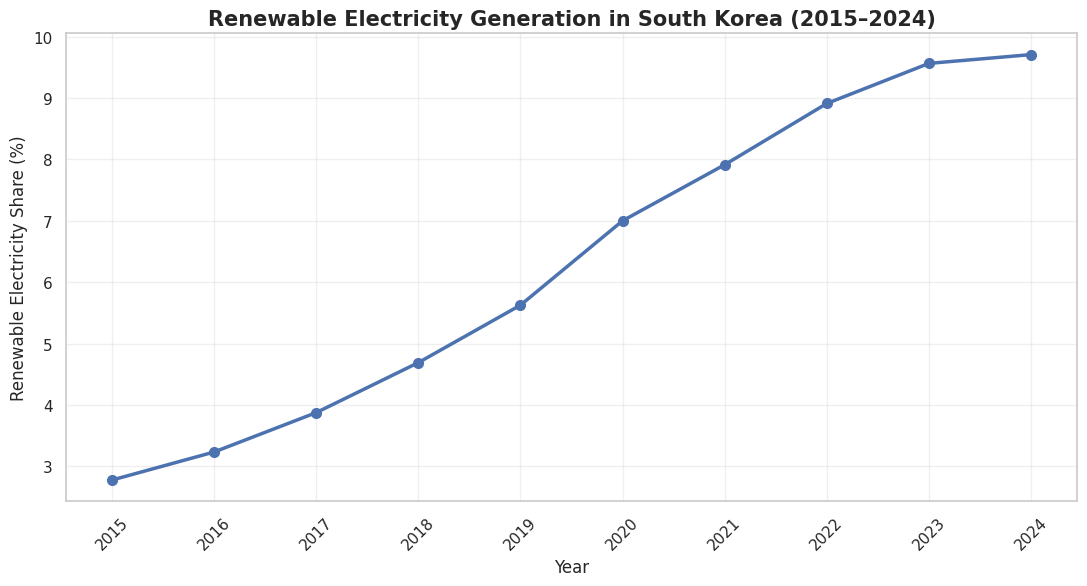

In [24]:

plt.figure(figsize=(11, 6))


plt.plot(
    combined_data["date"],
    combined_data["renewable_electricity_share_pct"],
    marker="o",
    linewidth=2.5,
    markersize=7
)


plt.title(
    "Renewable Electricity Generation in South Korea (2015–2024)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Renewable Electricity Share (%)", fontsize=12)


plt.xticks(combined_data["date"], rotation=45)


plt.grid(True, alpha=0.3)


plt.tight_layout()

plt.show()


### Preliminary Finding: Renewable Electricity Growth

South Korea experienced a sustained increase in renewable electricity's share of total electricity generation between 2015 and 2024. The share increased from approximately 2.77% in 2015 to 9.71% in 2024, representing an increase of approximately 6.93 percentage points.

This trend suggests that renewable electricity became a progressively larger component of South Korea's electricity mix during the study period. Further analysis will examine how this development relates to economic growth, electricity-sector emissions, and changes in the country's energy mix.

*Note: This is a descriptive finding and does not establish a causal relationship.*

In [25]:

x = combined_data["renewable_electricity_share_pct"]
y = combined_data["gdp_growth_pct"]


pearson_r, pearson_p = stats.pearsonr(x, y)

spearman_r, spearman_p = stats.spearmanr(x, y)


print("CORRELATION ANALYSIS: SOUTH KOREA")
print("---------------------------------")

print(f"Number of observations: {len(combined_data)}")

print(f"\nPearson correlation: {pearson_r:.4f}")
print(f"Pearson p-value: {pearson_p:.4f}")

print(f"\nSpearman correlation: {spearman_r:.4f}")
print(f"Spearman p-value: {spearman_p:.4f}")


CORRELATION ANALYSIS: SOUTH KOREA
---------------------------------
Number of observations: 10

Pearson correlation: -0.2895
Pearson p-value: 0.4172

Spearman correlation: -0.4788
Spearman p-value: 0.1615


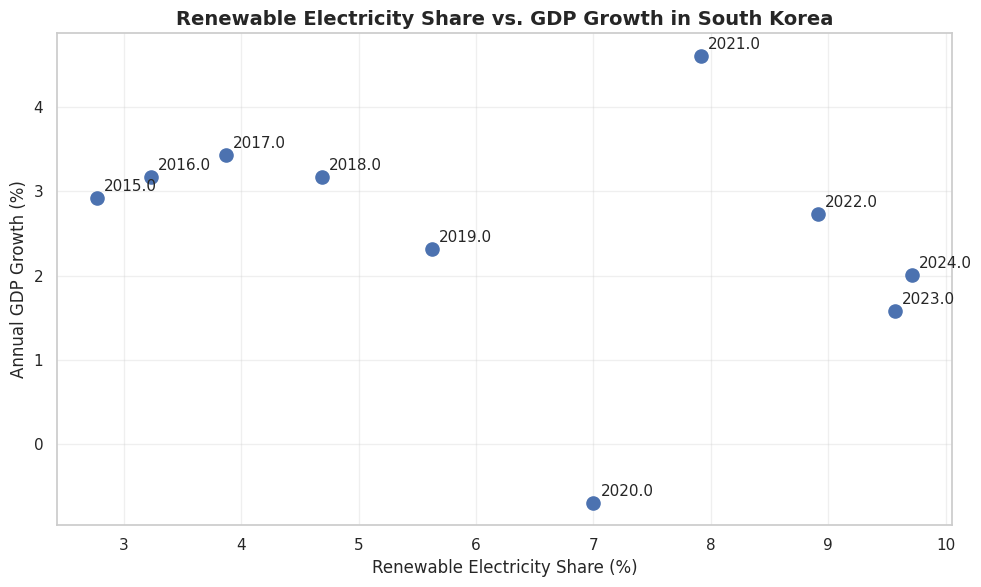

In [26]:

plt.figure(figsize=(10, 6))


plt.scatter(
    combined_data["renewable_electricity_share_pct"],
    combined_data["gdp_growth_pct"],
    s=90
)


for _, row in combined_data.iterrows():
    plt.annotate(
        str(row["date"]),
        (
            row["renewable_electricity_share_pct"],
            row["gdp_growth_pct"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )


plt.title(
    "Renewable Electricity Share vs. GDP Growth in South Korea",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Renewable Electricity Share (%)")
plt.ylabel("Annual GDP Growth (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Preliminary Finding: Renewable Electricity and Economic Growth

A correlation analysis was conducted to examine the relationship between renewable electricity's share of total generation and South Korea's annual GDP growth from 2015 to 2024.

The Pearson correlation coefficient was -0.2895, indicating a weak negative linear association. The Spearman rank correlation coefficient was -0.4788, indicating a moderately negative association in the rankings of the two variables.

Neither result was statistically significant at the 5% level (Pearson p = 0.4172; Spearman p = 0.1615).

These findings do not provide sufficient evidence of a statistically significant relationship between renewable electricity share and annual GDP growth during the study period. The small sample size of ten annual observations limits the strength of the conclusions. Further analysis should examine potential influences, including the exceptional economic conditions in 2020, before drawing broader conclusions.

Importantly, correlation does not establish causation.

In [57]:


data_without_2020 = combined_data[
    combined_data["date"] != 2020
].copy()


pearson_no_2020 = stats.pearsonr(
    data_without_2020["renewable_electricity_share_pct"],
    data_without_2020["gdp_growth_pct"]
)

spearman_no_2020 = stats.spearmanr(
    data_without_2020["renewable_electricity_share_pct"],
    data_without_2020["gdp_growth_pct"]
)


print("SENSITIVITY ANALYSIS")
print("--------------------")

print("Original Pearson:", round(pearson_r, 4))
print("Without 2020 Pearson:", round(pearson_no_2020.statistic, 4))

print("\nOriginal Spearman:", round(spearman_r, 4))
print("Without 2020 Spearman:", round(spearman_no_2020.statistic, 4))

print("\nObservations without 2020:", len(data_without_2020))


SENSITIVITY ANALYSIS
--------------------
Original Pearson: 0.7775
Without 2020 Pearson: -0.3685

Original Spearman: 0.7833
Without 2020 Spearman: -0.55

Observations without 2020: 9


### Sensitivity Analysis: Influence of 2020

To evaluate the influence of the 2020 economic disruption, the correlation analysis was repeated after excluding 2020.

The Pearson correlation changed from -0.2895 to -0.3685, while the Spearman correlation changed from -0.4788 to -0.5500.

Both coefficients became more negative after excluding 2020. This suggests that the observed negative association was not solely attributable to the 2020 observation. However, the analysis still contains only nine annual observations, and the results should be interpreted cautiously.

The original ten-year analysis remains the primary analysis. The exclusion of 2020 is presented only as a sensitivity check.

In [56]:

carbon_url = (
    "https://ourworldindata.org/grapher/electricity-mix.csv"
    "?v=1&csvType=full&useColumnShortNames=false"
    "&source=total&metric=carbon_intensity"
    "&frequency=annual"
)

carbon_response = requests.get(
    carbon_url,
    headers={"User-Agent": "Our World In Data data fetch/1.0"},
    timeout=30
)

carbon_response.raise_for_status()


carbon_raw = pd.read_csv(StringIO(carbon_response.text))


print("CARBON DATASET COLUMNS")
print("----------------------")
print(carbon_raw.columns.tolist())

print("\nFirst five rows:")
display(carbon_raw.head())


CARBON DATASET COLUMNS
----------------------
['Entity', 'Code', 'Year', 'Carbon intensity']

First five rows:


,Entity,Code,Year,Carbon intensity
0,ASEAN (Ember),NaN,2000,572.58
1,ASEAN (Ember),NaN,2001,570.27
2,ASEAN (Ember),NaN,2002,572.68
3,ASEAN (Ember),NaN,2003,577.02
4,ASEAN (Ember),NaN,2004,583.64


In [29]:


kor_carbon = carbon_raw[
    carbon_raw["Code"] == "KOR"
].copy()


kor_carbon = kor_carbon[
    kor_carbon["Year"].between(START_YEAR, END_YEAR)
].copy()

carbon_columns = [
    col for col in kor_carbon.columns
    if col not in ["Entity", "Code", "Year"]
]

print("Carbon measurement column:", carbon_columns)


kor_carbon = kor_carbon[["Year", carbon_columns[0]]].copy()

kor_carbon.columns = [
    "date",
    "electricity_carbon_intensity_gco2e_kwh"
]

kor_carbon["electricity_carbon_intensity_gco2e_kwh"] = pd.to_numeric(
    kor_carbon["electricity_carbon_intensity_gco2e_kwh"],
    errors="coerce"
)


kor_carbon = kor_carbon.sort_values("date").reset_index(drop=True)


print("\nSOUTH KOREA: ELECTRICITY CARBON INTENSITY")
display(kor_carbon)

print("\nMissing values:")
print(kor_carbon.isnull().sum())


Carbon measurement column: ['Carbon intensity']

SOUTH KOREA: ELECTRICITY CARBON INTENSITY


,date,electricity_carbon_intensity_gco2e_kwh
0,2015,487.64
1,2016,489.38
2,2017,511.48
3,2018,518.81
4,2019,496.97
5,2020,457.63
6,2021,459.46
7,2022,438.06
8,2023,427.29
9,2024,415.51



Missing values:
date                                      0
electricity_carbon_intensity_gco2e_kwh    0
dtype: int64


In [30]:


combined_data = pd.merge(
    combined_data,
    kor_carbon,
    on="date",
    how="left",
    validate="one_to_one"
)


print("COMBINED SOUTH KOREA DATASET")
display(combined_data)

print("\nMissing values:")
print(combined_data.isnull().sum())

print("\nDataset dimensions:")
print(combined_data.shape)


COMBINED SOUTH KOREA DATASET


,date,gdp_constant_2015_usd,gdp_growth_pct,renewable_electricity_share_pct,electricity_carbon_intensity_gco2e_kwh
0,2015,1.539212e+12,2.920293,2.774735,487.64
1,2016,1.588029e+12,3.171527,3.231844,489.38
2,2017,1.642549e+12,3.433192,3.873979,511.48
3,2018,1.694718e+12,3.176116,4.688739,518.81
4,2019,1.733931e+12,2.313802,5.625426,496.97
5,2020,1.721789e+12,-0.700242,7.000399,457.63
6,2021,1.801214e+12,4.612968,7.914308,459.46
7,2022,1.850344e+12,2.727565,8.912767,438.06
8,2023,1.879635e+12,1.583015,9.566147,427.29
9,2024,1.917296e+12,2.003611,9.709297,415.51



Missing values:
date                                      0
gdp_constant_2015_usd                     0
gdp_growth_pct                            0
renewable_electricity_share_pct           0
electricity_carbon_intensity_gco2e_kwh    0
dtype: int64

Dataset dimensions:
(10, 5)


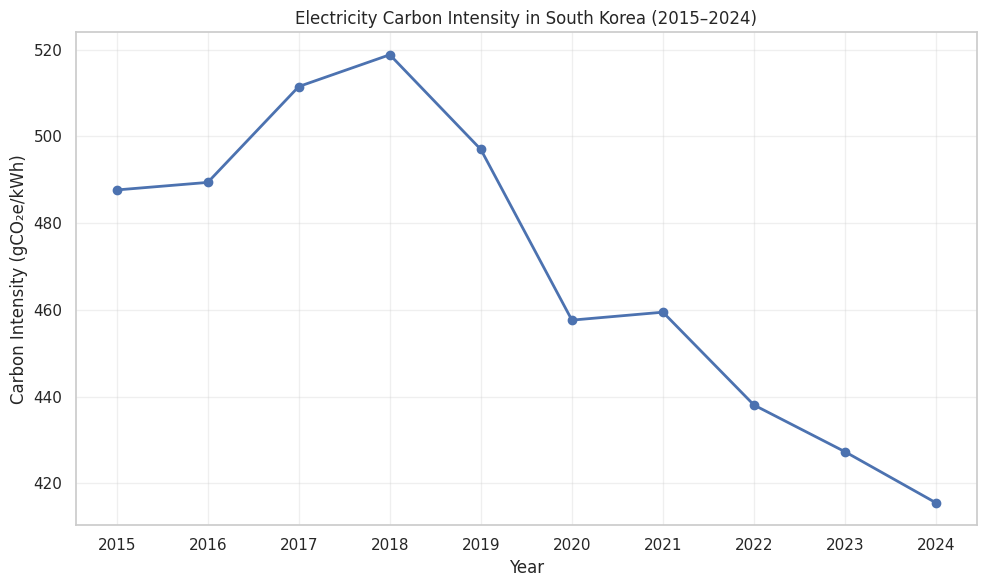

In [31]:

plt.figure(figsize=(10, 6))

plt.plot(
    combined_data["date"],
    combined_data["electricity_carbon_intensity_gco2e_kwh"],
    marker="o",
    linewidth=2
)

plt.title(
    "Electricity Carbon Intensity in South Korea (2015–2024)"
)
plt.xlabel("Year")
plt.ylabel("Carbon Intensity (gCO₂e/kWh)")
plt.xticks(combined_data["date"])
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [32]:



x = combined_data["renewable_electricity_share_pct"]
y = combined_data["electricity_carbon_intensity_gco2e_kwh"]


pearson_r, pearson_p = stats.pearsonr(x, y)


spearman_r, spearman_p = stats.spearmanr(x, y)

print("RENEWABLE ELECTRICITY vs. CARBON INTENSITY")
print("-----------------------------------------")
print("Number of observations:", len(combined_data))
print(f"Pearson correlation: {pearson_r:.4f}")
print(f"Pearson p-value: {pearson_p:.4f}")
print(f"Spearman correlation: {spearman_r:.4f}")
print(f"Spearman p-value: {spearman_p:.4f}")


RENEWABLE ELECTRICITY vs. CARBON INTENSITY
-----------------------------------------
Number of observations: 10
Pearson correlation: -0.8819
Pearson p-value: 0.0007
Spearman correlation: -0.7818
Spearman p-value: 0.0075


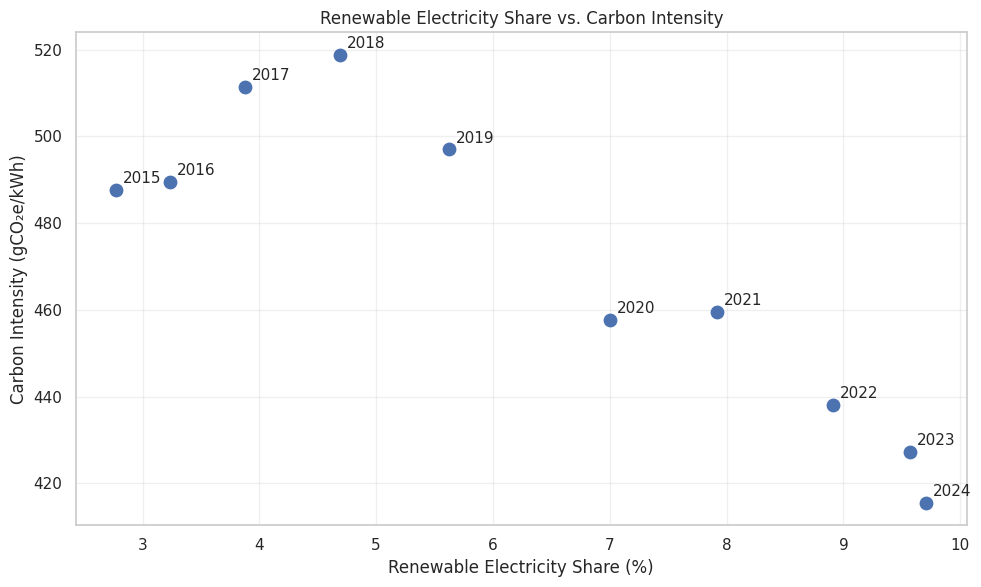

In [33]:

plt.figure(figsize=(10, 6))

plt.scatter(
    combined_data["renewable_electricity_share_pct"],
    combined_data["electricity_carbon_intensity_gco2e_kwh"],
    s=80
)


for _, row in combined_data.iterrows():
    plt.annotate(
        str(int(row["date"])),
        (
            row["renewable_electricity_share_pct"],
            row["electricity_carbon_intensity_gco2e_kwh"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Renewable Electricity Share vs. Carbon Intensity")
plt.xlabel("Renewable Electricity Share (%)")
plt.ylabel("Carbon Intensity (gCO₂e/kWh)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [34]:


annual_changes = combined_data[
    ["date", "renewable_electricity_share_pct",
     "electricity_carbon_intensity_gco2e_kwh"]
].copy()

annual_changes["renewable_change"] = (
    annual_changes["renewable_electricity_share_pct"].diff()
)

annual_changes["carbon_intensity_change"] = (
    annual_changes["electricity_carbon_intensity_gco2e_kwh"].diff()
)


annual_changes = annual_changes.dropna()


change_r, change_p = stats.pearsonr(
    annual_changes["renewable_change"],
    annual_changes["carbon_intensity_change"]
)

print("YEAR-TO-YEAR CHANGE ANALYSIS")
print("----------------------------")
print("Number of annual changes:", len(annual_changes))
print(f"Pearson correlation: {change_r:.4f}")
print(f"Pearson p-value: {change_p:.4f}")

display(annual_changes)


YEAR-TO-YEAR CHANGE ANALYSIS
----------------------------
Number of annual changes: 9
Pearson correlation: -0.5106
Pearson p-value: 0.1601


,date,renewable_electricity_share_pct,electricity_carbon_intensity_gco2e_kwh,renewable_change,carbon_intensity_change
1,2016,3.231844,489.38,0.457109,1.74
2,2017,3.873979,511.48,0.642135,22.10
3,2018,4.688739,518.81,0.814760,7.33
4,2019,5.625426,496.97,0.936687,-21.84
5,2020,7.000399,457.63,1.374973,-39.34
6,2021,7.914308,459.46,0.913909,1.83
7,2022,8.912767,438.06,0.998459,-21.40
8,2023,9.566147,427.29,0.653380,-10.77
9,2024,9.709297,415.51,0.143150,-11.78


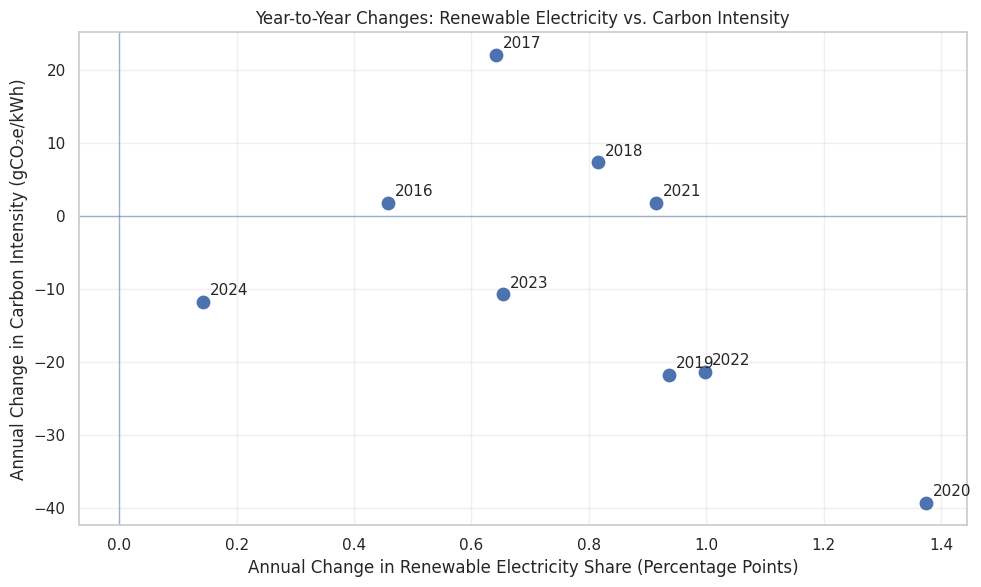

In [35]:


annual_changes = combined_data.sort_values("date").copy()

annual_changes["renewable_change"] = (
    annual_changes["renewable_electricity_share_pct"].diff()
)

annual_changes["carbon_intensity_change"] = (
    annual_changes["electricity_carbon_intensity_gco2e_kwh"].diff()
)


annual_changes = annual_changes.dropna(
    subset=["renewable_change", "carbon_intensity_change"]
)


plt.figure(figsize=(10, 6))

plt.scatter(
    annual_changes["renewable_change"],
    annual_changes["carbon_intensity_change"],
    s=80
)

for _, row in annual_changes.iterrows():
    plt.annotate(
        str(int(row["date"])),
        (row["renewable_change"], row["carbon_intensity_change"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axhline(0, linewidth=1, alpha=0.5)
plt.axvline(0, linewidth=1, alpha=0.5)

plt.title("Year-to-Year Changes: Renewable Electricity vs. Carbon Intensity")
plt.xlabel("Annual Change in Renewable Electricity Share (Percentage Points)")
plt.ylabel("Annual Change in Carbon Intensity (gCO₂e/kWh)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Preliminary Finding: Year-to-Year Changes

An additional analysis examined the relationship between annual changes in renewable electricity share and annual changes in electricity carbon intensity in South Korea from 2016 to 2024. The Pearson correlation coefficient was -0.5106, indicating a moderate negative association. However, the p-value was 0.1601, meaning the relationship was not statistically significant at the 5% significance level. These results suggest that increases in renewable electricity share tended to coincide with decreases in electricity carbon intensity, although the limited number of observations prevents a definitive statistical conclusion.

In [36]:


from io import StringIO

sources = ["coal", "gas", "nuclear", "renewables"]

generation_data = None

for source in sources:

    url = (
        "https://ourworldindata.org/grapher/electricity-mix.csv"
        "?v=1&csvType=full&useColumnShortNames=false"
        f"&source={source}&metric=share_of_generation&frequency=annual"
    )

    response = requests.get(
        url,
        headers={"User-Agent": "Our World In Data data fetch/1.0"},
        timeout=30
    )
    response.raise_for_status()

    source_df = pd.read_csv(StringIO(response.text))


    source_df = source_df[
        (source_df["Code"] == "KOR") &
        (source_df["Year"].between(START_YEAR, END_YEAR))
    ].copy()


    value_columns = [
        col for col in source_df.columns
        if col not in ["Entity", "Code", "Year"]
    ]

    if len(value_columns) != 1:
        raise ValueError(
            f"Unexpected columns for {source}: {source_df.columns.tolist()}"
        )

    source_df = source_df[["Year", value_columns[0]]].copy()

    source_df = source_df.rename(columns={
        "Year": "date",
        value_columns[0]: f"{source}_share_pct"
    })

    if generation_data is None:
        generation_data = source_df
    else:
        generation_data = pd.merge(
            generation_data,
            source_df,
            on="date",
            how="outer",
            validate="one_to_one"
        )

generation_data = generation_data.sort_values("date").reset_index(drop=True)

print("SOUTH KOREA ELECTRICITY GENERATION MIX")
display(generation_data)

print("\nMissing values:")
print(generation_data.isnull().sum())


SOUTH KOREA ELECTRICITY GENERATION MIX


,date,coal_share_pct,gas_share_pct,nuclear_share_pct,renewables_share_pct
0,2015,42.475357,22.276379,30.076670,2.774735
1,2016,41.518417,23.266428,28.876255,3.231844
2,2017,45.243840,23.448590,25.750767,3.873979
3,2018,43.458538,27.538750,22.517752,4.688739
4,2019,41.758690,26.484324,24.865372,5.625426
5,2020,36.036457,28.164474,27.755540,7.000399
6,2021,35.099380,29.819336,25.998749,7.914308
7,2022,33.604780,28.061806,28.277035,8.912767
8,2023,32.606197,27.467651,29.229624,9.566147
9,2024,30.506252,28.518661,30.181650,9.709297



Missing values:
date                    0
coal_share_pct          0
gas_share_pct           0
nuclear_share_pct       0
renewables_share_pct    0
dtype: int64


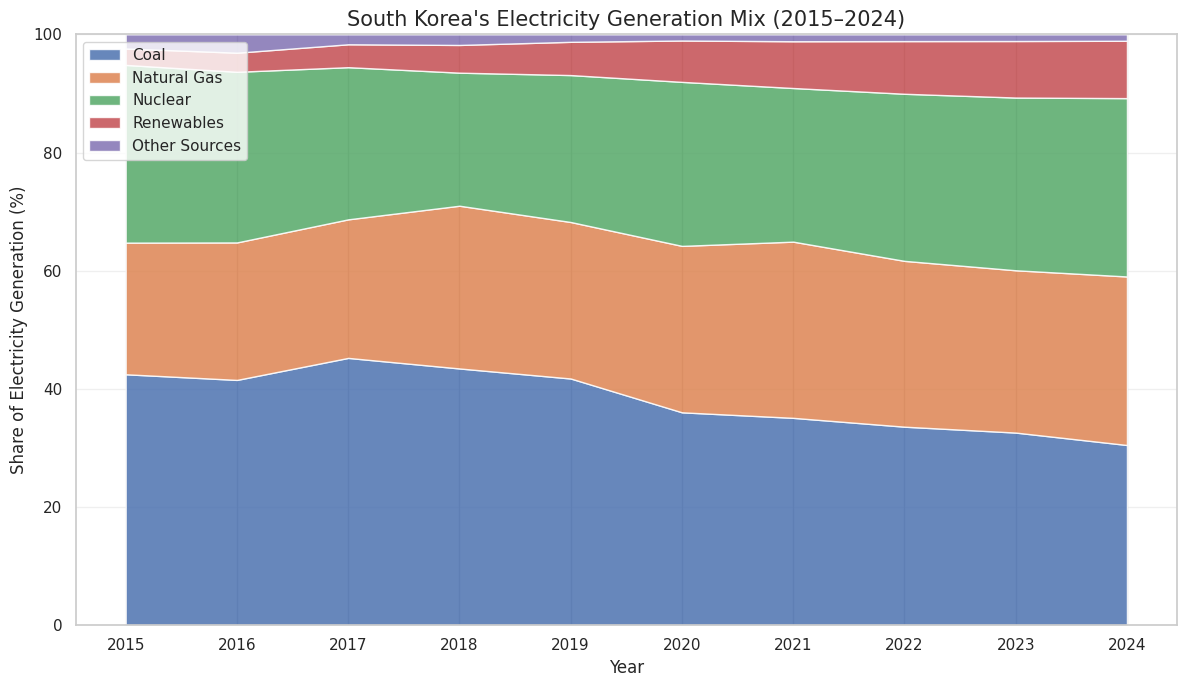

In [41]:


plt.figure(figsize=(12, 7))

plt.stackplot(
    generation_data["date"],
    generation_data["coal_share_pct"],
    generation_data["gas_share_pct"],
    generation_data["nuclear_share_pct"],
    generation_data["renewables_share_pct"],
    generation_data["other_sources_pct"],
    labels=[
        "Coal",
        "Natural Gas",
        "Nuclear",
        "Renewables",
        "Other Sources"
    ],
    alpha=0.85
)

plt.title(
    "South Korea's Electricity Generation Mix (2015–2024)",
    fontsize=15
)
plt.xlabel("Year")
plt.ylabel("Share of Electricity Generation (%)")

plt.xticks(generation_data["date"])
plt.ylim(0, 100)
plt.legend(loc="upper left")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



In [38]:



first_year = generation_data.iloc[0]
last_year = generation_data.iloc[-1]

comparison = pd.DataFrame({
    "Energy Source": ["Coal", "Natural Gas", "Nuclear", "Renewables"],
    "2015 Share (%)": [
        first_year["coal_share_pct"],
        first_year["gas_share_pct"],
        first_year["nuclear_share_pct"],
        first_year["renewables_share_pct"]
    ],
    "2024 Share (%)": [
        last_year["coal_share_pct"],
        last_year["gas_share_pct"],
        last_year["nuclear_share_pct"],
        last_year["renewables_share_pct"]
    ]
})

comparison["Change (Percentage Points)"] = (
    comparison["2024 Share (%)"] - comparison["2015 Share (%)"]
)

print("ELECTRICITY GENERATION MIX: 2015 VS. 2024")
display(comparison.round(2))


ELECTRICITY GENERATION MIX: 2015 VS. 2024


,Energy Source,2015 Share (%),2024 Share (%),Change (Percentage Points)
0,Coal,42.48,30.51,-11.97
1,Natural Gas,22.28,28.52,6.24
2,Nuclear,30.08,30.18,0.10
3,Renewables,2.77,9.71,6.93


In [42]:




generation_data["total_selected_sources_pct"] = (
    generation_data["coal_share_pct"]
    + generation_data["gas_share_pct"]
    + generation_data["nuclear_share_pct"]
    + generation_data["renewables_share_pct"]
)

generation_data["other_sources_pct"] = (
    100 - generation_data["total_selected_sources_pct"]
)

print("ELECTRICITY GENERATION SHARE CHECK")
display(
    generation_data[
        ["date", "total_selected_sources_pct", "other_sources_pct"]
    ].round(2)
)

print("\nLargest remaining share:")
print(generation_data["other_sources_pct"].max())


ELECTRICITY GENERATION SHARE CHECK


,date,total_selected_sources_pct,other_sources_pct
0,2015,97.60,2.40
1,2016,96.89,3.11
2,2017,98.32,1.68
3,2018,98.20,1.80
4,2019,98.73,1.27
5,2020,98.96,1.04
6,2021,98.83,1.17
7,2022,98.86,1.14
8,2023,98.87,1.13
9,2024,98.92,1.08



Largest remaining share:
3.1070557999999977


### Preliminary Finding: Changes in South Korea's Electricity Generation Mix

Between 2015 and 2024, South Korea experienced a notable shift in its electricity generation mix. Coal's share declined from 42.48% to 30.51%, a reduction of 11.97 percentage points. Renewable electricity increased from 2.77% to 9.71%, while natural gas increased from 22.28% to 28.52%. Nuclear power remained relatively stable, changing by only 0.10 percentage points.

These findings suggest that South Korea's electricity transition involved a combination of declining coal generation and increasing contributions from renewable energy and natural gas. The changes in the generation mix provide important context for interpreting the decline in electricity carbon intensity observed during the same period. However, these descriptive trends alone do not establish which energy source caused the emissions-intensity reduction.

In [55]:


renewable_comparison = pd.DataFrame({
    "date": combined_data["date"],
    "renewables_original_pct": combined_data[
        "renewable_electricity_share_pct"
    ],
    "renewables_mix_pct": generation_data[
        "renewables_share_pct"
    ]
})

renewable_comparison["difference"] = (
    renewable_comparison["renewables_original_pct"]
    - renewable_comparison["renewables_mix_pct"]
)

print("RENEWABLE DATA SOURCE COMPARISON")
display(renewable_comparison.round(4))

print(
    "\nMaximum absolute difference:",
    renewable_comparison["difference"].abs().max()
)


RENEWABLE DATA SOURCE COMPARISON


,date,renewables_original_pct,renewables_mix_pct,difference
0,2015,2.7747,2.7747,0.0
1,2016,3.2318,3.2318,0.0
2,2017,3.8740,3.8740,0.0
3,2018,4.6887,4.6887,0.0
4,2019,5.6254,5.6254,0.0
5,2020,7.0004,7.0004,0.0
6,2021,7.9143,7.9143,0.0
7,2022,8.9128,8.9128,0.0
8,2023,9.5661,9.5661,0.0
9,2024,9.7093,9.7093,0.0



Maximum absolute difference: 0.0


In [44]:


generation_to_merge = generation_data[
    [
        "date",
        "coal_share_pct",
        "gas_share_pct",
        "nuclear_share_pct",
        "other_sources_pct"
    ]
].copy()


combined_data = pd.merge(
    combined_data,
    generation_to_merge,
    on="date",
    how="left",
    validate="one_to_one"
)

print("UPDATED RESEARCH DATASET")
display(combined_data)

print("\nMissing values:")
print(combined_data.isnull().sum())


UPDATED RESEARCH DATASET


,date,gdp_constant_2015_usd,gdp_growth_pct,renewable_electricity_share_pct,electricity_carbon_intensity_gco2e_kwh,coal_share_pct,gas_share_pct,nuclear_share_pct,other_sources_pct
0,2015,1.539212e+12,2.920293,2.774735,487.64,42.475357,22.276379,30.076670,2.396858
1,2016,1.588029e+12,3.171527,3.231844,489.38,41.518417,23.266428,28.876255,3.107056
2,2017,1.642549e+12,3.433192,3.873979,511.48,45.243840,23.448590,25.750767,1.682824
3,2018,1.694718e+12,3.176116,4.688739,518.81,43.458538,27.538750,22.517752,1.796221
4,2019,1.733931e+12,2.313802,5.625426,496.97,41.758690,26.484324,24.865372,1.266188
5,2020,1.721789e+12,-0.700242,7.000399,457.63,36.036457,28.164474,27.755540,1.043130
6,2021,1.801214e+12,4.612968,7.914308,459.46,35.099380,29.819336,25.998749,1.168227
7,2022,1.850344e+12,2.727565,8.912767,438.06,33.604780,28.061806,28.277035,1.143612
8,2023,1.879635e+12,1.583015,9.566147,427.29,32.606197,27.467651,29.229624,1.130381
9,2024,1.917296e+12,2.003611,9.709297,415.51,30.506252,28.518661,30.181650,1.084140



Missing values:
date                                      0
gdp_constant_2015_usd                     0
gdp_growth_pct                            0
renewable_electricity_share_pct           0
electricity_carbon_intensity_gco2e_kwh    0
coal_share_pct                            0
gas_share_pct                             0
nuclear_share_pct                         0
other_sources_pct                         0
dtype: int64


In [47]:


energy_sources = {
    "Coal": "coal_share_pct",
    "Natural Gas": "gas_share_pct",
    "Nuclear": "nuclear_share_pct",
    "Renewables": "renewable_electricity_share_pct"
}

carbon_intensity = combined_data[
    "electricity_carbon_intensity_gco2e_kwh"
]

results = []

for source_name, column in energy_sources.items():

    pearson_r, pearson_p = stats.pearsonr(
        combined_data[column],
        carbon_intensity
    )

    spearman_r, spearman_p = stats.spearmanr(
        combined_data[column],
        carbon_intensity
    )

    results.append({
        "Energy Source": source_name,
        "Pearson Correlation": pearson_r,
        "Pearson p-value": pearson_p,
        "Spearman Correlation": spearman_r,
        "Spearman p-value": spearman_p
    })

correlation_results = pd.DataFrame(results)

print("ELECTRICITY SOURCES vs. CARBON INTENSITY")
print("----------------------------------------")
display(correlation_results.round(4))


ELECTRICITY SOURCES vs. CARBON INTENSITY
----------------------------------------


,Energy Source,Pearson Correlation,Pearson p-value,Spearman Correlation,Spearman p-value
0,Coal,0.9781,0.0000,0.9394,0.0001
1,Natural Gas,-0.5642,0.0893,-0.5030,0.1383
2,Nuclear,-0.6767,0.0316,-0.7576,0.0111
3,Renewables,-0.8819,0.0007,-0.7818,0.0075


In [46]:


energy_sources = {
    "Coal": "coal_share_pct",
    "Natural Gas": "gas_share_pct",
    "Nuclear": "nuclear_share_pct",
    "Renewables": "renewable_electricity_share_pct"
}

carbon_intensity = combined_data[
    "electricity_carbon_intensity_gco2e_kwh"
]

results = []

for source_name, column in energy_sources.items():

    pearson_r, pearson_p = stats.pearsonr(
        combined_data[column],
        carbon_intensity
    )

    spearman_r, spearman_p = stats.spearmanr(
        combined_data[column],
        carbon_intensity
    )

    results.append({
        "Energy Source": source_name,
        "Pearson Correlation": pearson_r,
        "Pearson p-value": pearson_p,
        "Spearman Correlation": spearman_r,
        "Spearman p-value": spearman_p
    })

correlation_results = pd.DataFrame(results)

print("ELECTRICITY SOURCES vs. CARBON INTENSITY")
print("----------------------------------------")
display(correlation_results.round(4))


ELECTRICITY SOURCES vs. CARBON INTENSITY
----------------------------------------


,Energy Source,Pearson Correlation,Pearson p-value,Spearman Correlation,Spearman p-value
0,Coal,0.9781,0.0000,0.9394,0.0001
1,Natural Gas,-0.5642,0.0893,-0.5030,0.1383
2,Nuclear,-0.6767,0.0316,-0.7576,0.0111
3,Renewables,-0.8819,0.0007,-0.7818,0.0075


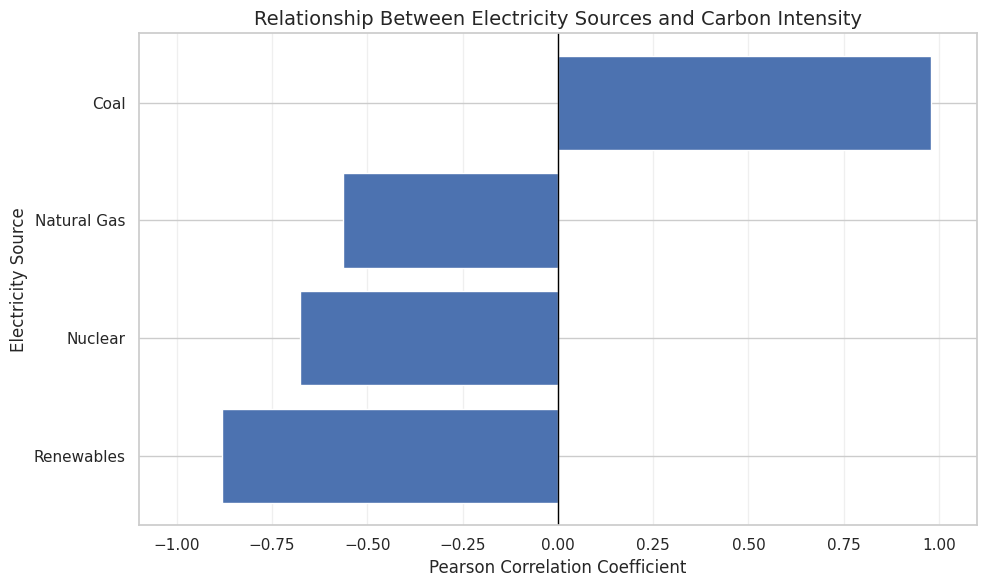

In [48]:

plot_data = correlation_results.sort_values(
    "Pearson Correlation"
)

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Energy Source"],
    plot_data["Pearson Correlation"]
)

plt.axvline(0, color="black", linewidth=1)

plt.title(
    "Relationship Between Electricity Sources and Carbon Intensity",
    fontsize=14
)
plt.xlabel("Pearson Correlation Coefficient")
plt.ylabel("Electricity Source")
plt.xlim(-1.1, 1.1)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()


**Preliminary Finding: Electricity Generation Sources and Carbon Intensity**

Correlation analysis revealed substantial relationships between South Korea's electricity generation mix and electricity carbon intensity during 2015–2024. Coal share had a very strong positive correlation with carbon intensity (Pearson r = 0.9781, p < 0.001), while renewable electricity share had a very strong negative correlation (r = -0.8819, p = 0.0007). Nuclear generation also showed a statistically significant negative association (r = -0.6767, p = 0.0316). Natural gas had a moderate negative correlation, but this result was not statistically significant at the 5% level (r = -0.5642, p = 0.0893).

These findings suggest that changes in coal, renewable, and nuclear generation shares were closely associated with changes in electricity carbon intensity. However, the analysis is exploratory and based on only ten annual observations. Because electricity generation shares are interconnected, the correlations should not be interpreted as independent causal effects. Further analysis would be necessary to distinguish the contributions of individual electricity sources.

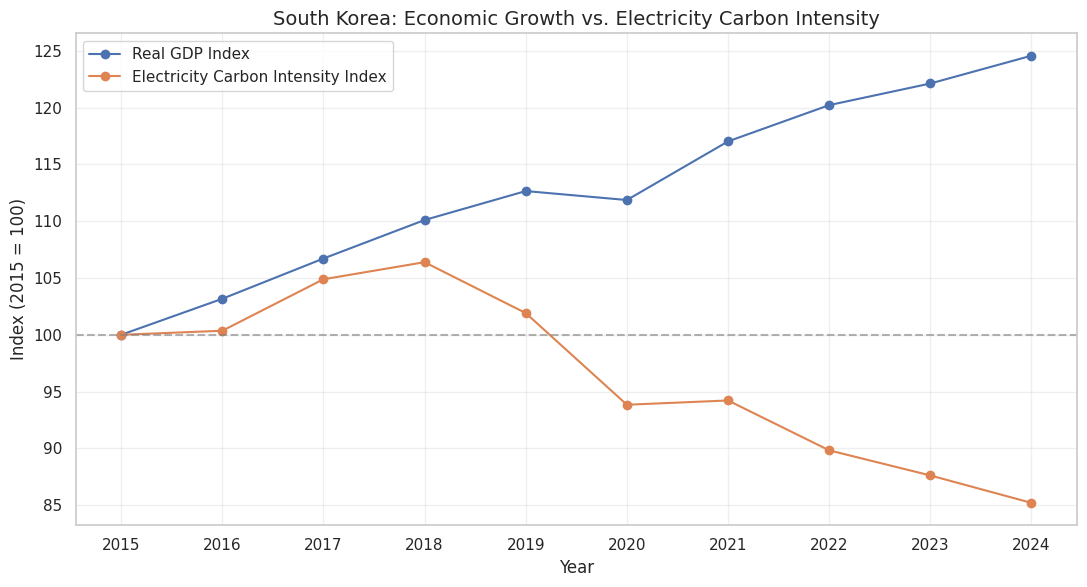

In [54]:

trend_data = combined_data.sort_values("date").copy()

trend_data["gdp_index"] = (
    trend_data["gdp_constant_2015_usd"]
    / trend_data["gdp_constant_2015_usd"].iloc[0]
) * 100

trend_data["carbon_index"] = (
    trend_data["electricity_carbon_intensity_gco2e_kwh"]
    / trend_data["electricity_carbon_intensity_gco2e_kwh"].iloc[0]
) * 100

plt.figure(figsize=(11, 6))

plt.plot(
    trend_data["date"],
    trend_data["gdp_index"],
    marker="o",
    label="Real GDP Index"
)

plt.plot(
    trend_data["date"],
    trend_data["carbon_index"],
    marker="o",
    label="Electricity Carbon Intensity Index"
)

plt.axhline(100, color="gray", linestyle="--", alpha=0.6)

plt.title(
    "South Korea: Economic Growth vs. Electricity Carbon Intensity",
    fontsize=14
)
plt.xlabel("Year")
plt.ylabel("Index (2015 = 100)")
plt.xticks(trend_data["date"])
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [50]:



gdp_change = (
    (trend_data["gdp_constant_2015_usd"].iloc[-1]
     / trend_data["gdp_constant_2015_usd"].iloc[0]) - 1
) * 100

carbon_change = (
    (trend_data["electricity_carbon_intensity_gco2e_kwh"].iloc[-1]
     / trend_data["electricity_carbon_intensity_gco2e_kwh"].iloc[0]) - 1
) * 100

print("ECONOMIC AND ENVIRONMENTAL CHANGE: 2015–2024")
print("---------------------------------------------")
print(f"Real GDP change: {gdp_change:.2f}%")
print(f"Electricity carbon intensity change: {carbon_change:.2f}%")


ECONOMIC AND ENVIRONMENTAL CHANGE: 2015–2024
---------------------------------------------
Real GDP change: 24.56%
Electricity carbon intensity change: -14.79%


In [52]:


economic_changes = combined_data.sort_values("date").copy()

# Calculate annual percentage changes in carbon intensity
economic_changes["carbon_intensity_annual_change_pct"] = (
    economic_changes["electricity_carbon_intensity_gco2e_kwh"]
    .pct_change() * 100
)

# GDP growth is already expressed as an annual percentage
economic_changes = economic_changes.dropna(
    subset=["carbon_intensity_annual_change_pct"]
)

# Correlation analysis
pearson_r, pearson_p = stats.pearsonr(
    economic_changes["gdp_growth_pct"],
    economic_changes["carbon_intensity_annual_change_pct"]
)

spearman_r, spearman_p = stats.spearmanr(
    economic_changes["gdp_growth_pct"],
    economic_changes["carbon_intensity_annual_change_pct"]
)

print("GDP GROWTH vs. ANNUAL CARBON INTENSITY CHANGE")
print("---------------------------------------------")
print("Number of observations:", len(economic_changes))
print(f"Pearson correlation: {pearson_r:.4f}")
print(f"Pearson p-value: {pearson_p:.4f}")
print(f"Spearman correlation: {spearman_r:.4f}")
print(f"Spearman p-value: {spearman_p:.4f}")


GDP GROWTH vs. ANNUAL CARBON INTENSITY CHANGE
---------------------------------------------
Number of observations: 9
Pearson correlation: 0.7775
Pearson p-value: 0.0137
Spearman correlation: 0.7833
Spearman p-value: 0.0125


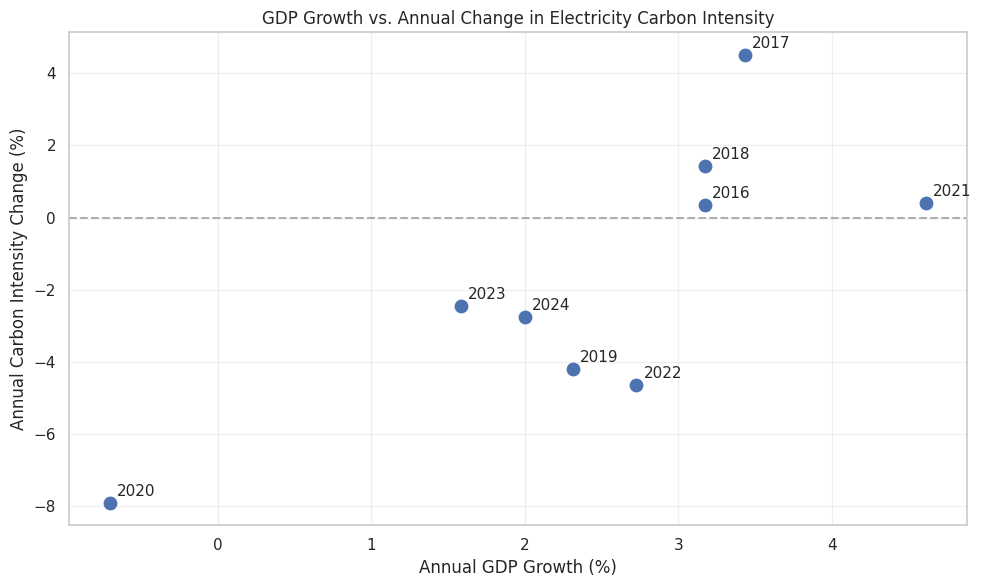

In [53]:

plt.figure(figsize=(10, 6))

plt.scatter(
    economic_changes["gdp_growth_pct"],
    economic_changes["carbon_intensity_annual_change_pct"],
    s=80
)

for _, row in economic_changes.iterrows():
    plt.annotate(
        str(int(row["date"])),
        (
            row["gdp_growth_pct"],
            row["carbon_intensity_annual_change_pct"]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axhline(0, color="gray", linestyle="--", alpha=0.6)

plt.title("GDP Growth vs. Annual Change in Electricity Carbon Intensity")
plt.xlabel("Annual GDP Growth (%)")
plt.ylabel("Annual Carbon Intensity Change (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


The analysis identified a statistically significant positive relationship between annual GDP growth and year-to-year changes in electricity carbon intensity in South Korea from 2015 to 2024. Pearson correlation (r = 0.7775, p = 0.0137) and Spearman correlation (ρ = 0.7833, p = 0.0125) both indicated a strong positive association. This suggests that years with stronger economic growth tended to coincide with less favorable annual changes in electricity carbon intensity. However, this relationship does not establish causation. The small sample size and the influence of other economic and energy-related factors should be considered when interpreting the results.

## Research Findings and Interpretation

## Overview

This study examined the relationship between renewable electricity adoption, electricity generation composition, carbon intensity, and economic growth in South Korea between 2015 and 2024. Using data from the World Bank and Our World in Data/Ember, the analysis combined descriptive statistics, trend visualizations, and Pearson and Spearman correlation tests.

The objective was to investigate whether South Korea's increasing use of renewable electricity was associated with changes in electricity-sector carbon intensity and economic performance.

## Key Research Findings

**Finding 1: Renewable electricity adoption increased substantially.**

South Korea's renewable electricity share increased from approximately 2.77% in 2015 to 9.71% in 2024, a gain of 6.93 percentage points. This demonstrates a clear increase in renewable electricity's contribution to the generation mix over the study period.

**Finding 2: The electricity generation mix changed between 2015 and 2024.**

Coal's share declined from 42.48% to 30.51%, while natural gas increased from 22.28% to 28.52%. Nuclear power remained relatively stable, increasing slightly from 30.08% to 30.18%. Renewable electricity increased from 2.77% to 9.71%.

**Finding 3: Renewable electricity share was strongly negatively associated with electricity carbon intensity.**

Pearson correlation was -0.8819 (p = 0.0007), while Spearman correlation was -0.7818 (p = 0.0075). Both tests indicated a statistically significant negative association between renewable electricity share and electricity carbon intensity.

**Finding 4: Coal share was strongly positively associated with electricity carbon intensity.**

Coal share had a Pearson correlation of +0.9781 (p approximately 0.0000 when rounded to four decimal places). Nuclear and renewable electricity shares were negatively associated with carbon intensity. These relationships are observational and should not be interpreted as independent causal effects.

**Finding 5: South Korea experienced economic growth alongside declining electricity carbon intensity.**

Between 2015 and 2024, real GDP increased by 24.56%, while electricity carbon intensity decreased by 14.79%. This pattern is consistent with relative decoupling between economic growth and electricity-sector carbon intensity.

**Finding 6: Annual GDP growth was positively associated with annual changes in electricity carbon intensity.**

Pearson correlation was +0.7775 (p = 0.0137), and Spearman correlation was +0.7833 (p = 0.0125). This suggests that years with stronger GDP growth tended to coincide with less favorable annual changes in electricity carbon intensity. However, this does not establish a causal relationship.

 ## Overall Interpretation

The findings suggest that South Korea made measurable progress in increasing renewable electricity generation and reducing electricity carbon intensity between 2015 and 2024. The strong negative association between renewable electricity share and carbon intensity is consistent with the possibility that the changing electricity generation mix contributed to a less carbon-intensive electricity sector.

At the same time, the positive association between annual GDP growth and annual carbon-intensity changes highlights that economic expansion and electricity-sector decarbonization do not necessarily move together consistently from year to year.

The overall findings indicate that economic growth and declining electricity carbon intensity occurred simultaneously over the study period, although the analysis cannot establish that renewable energy adoption directly caused either outcome.

## Research Limitations

Several limitations should be considered when interpreting the findings of this study.

**1. Limited sample size**

The analysis covers only ten annual observations from 2015 to 2024. Correlation results, particularly those involving annual changes, should therefore be interpreted cautiously because a small sample can make statistical estimates sensitive to individual years.

**2. Correlation does not establish causation**

The statistical relationships identified in this study do not demonstrate that renewable electricity adoption directly caused reductions in carbon intensity or changes in economic growth. Other factors, including energy policy, electricity demand, fuel prices, technological developments, and economic conditions, may have influenced the results.

**3. Electricity-sector scope**

The carbon-intensity indicator measures the carbon intensity of electricity generation rather than the carbon intensity of South Korea's entire economy. Consequently, the findings cannot establish that the country's overall economic growth has become less carbon-intensive.

**4. Interdependence of electricity sources**

Electricity generation shares are components of the same overall generation mix. An increase in one source's share can coincide with decreases in other sources. Therefore, individual correlations between generation sources and carbon intensity should not be interpreted as independent effects.

**5. Data availability and measurement**

The study relies on secondary datasets from the World Bank and Our World in Data/Ember. Differences in measurement definitions, data revisions, and reporting methodologies may affect comparisons and should be considered when interpreting the results.

## Final Conclusion

Between 2015 and 2024, South Korea experienced substantial growth in renewable electricity adoption alongside a measurable decline in electricity carbon intensity. Renewable electricity's share of generation increased from 2.77% to 9.71%, while electricity carbon intensity decreased by 14.79%. Over the same period, real GDP increased by 24.56%.

The statistical analysis identified a strong negative association between renewable electricity adoption and electricity carbon intensity. Coal generation also showed a strong positive association with carbon intensity, while nuclear generation showed a negative association.

Although the findings demonstrate that economic growth and declining electricity carbon intensity occurred simultaneously, the annual analysis highlights that their relationship was not consistently aligned from year to year.

Overall, this study provides evidence of a changing electricity generation mix and declining electricity carbon intensity in South Korea during the study period. Further research using longer time series, additional economic indicators, and more detailed energy-sector data could provide a deeper understanding of the relationship between renewable energy transitions, environmental outcomes, and economic development.

In [65]:

combined_data = (
    economic_data
    .merge(kor_renewables, on="date", how="inner")
    .merge(kor_carbon, on="date", how="inner")
    .merge(generation_to_merge, on="date", how="inner")
)


combined_data = combined_data.sort_values("date").reset_index(drop=True)


print("Dataset dimensions:", combined_data.shape)
print("\nColumns:")
print(combined_data.columns.tolist())

display(combined_data)

Dataset dimensions: (10, 9)

Columns:
['date', 'gdp_constant_2015_usd', 'gdp_growth_pct', 'renewable_electricity_share_pct', 'electricity_carbon_intensity_gco2e_kwh', 'coal_share_pct', 'gas_share_pct', 'nuclear_share_pct', 'other_sources_pct']


,date,gdp_constant_2015_usd,gdp_growth_pct,renewable_electricity_share_pct,electricity_carbon_intensity_gco2e_kwh,coal_share_pct,gas_share_pct,nuclear_share_pct,other_sources_pct
0,2015,1.539212e+12,2.920293,2.774735,487.64,42.475357,22.276379,30.076670,2.396858
1,2016,1.588029e+12,3.171527,3.231844,489.38,41.518417,23.266428,28.876255,3.107056
2,2017,1.642549e+12,3.433192,3.873979,511.48,45.243840,23.448590,25.750767,1.682824
3,2018,1.694718e+12,3.176116,4.688739,518.81,43.458538,27.538750,22.517752,1.796221
4,2019,1.733931e+12,2.313802,5.625426,496.97,41.758690,26.484324,24.865372,1.266188
5,2020,1.721789e+12,-0.700242,7.000399,457.63,36.036457,28.164474,27.755540,1.043130
6,2021,1.801214e+12,4.612968,7.914308,459.46,35.099380,29.819336,25.998749,1.168227
7,2022,1.850344e+12,2.727565,8.912767,438.06,33.604780,28.061806,28.277035,1.143612
8,2023,1.879635e+12,1.583015,9.566147,427.29,32.606197,27.467651,29.229624,1.130381
9,2024,1.917296e+12,2.003611,9.709297,415.51,30.506252,28.518661,30.181650,1.084140


In [66]:

combined_data.to_csv(
    "South_Korea_Renewable_Energy_Data.csv",
    index=False
)


from google.colab import files
files.download("South_Korea_Renewable_Energy_Data.csv")

print("SUCCESS: Final research dataset exported!")
print("Dimensions:", combined_data.shape)
print("Missing values:", combined_data.isnull().sum().sum())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

SUCCESS: Final research dataset exported!
Dimensions: (10, 9)
Missing values: 0


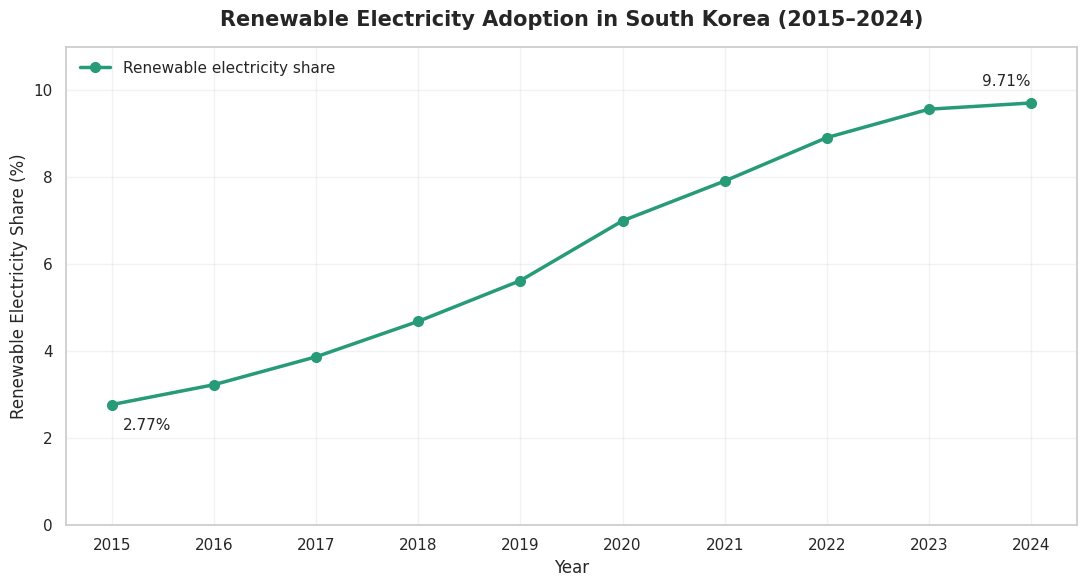

In [67]:


plt.figure(figsize=(11, 6))

plt.plot(
    combined_data["date"],
    combined_data["renewable_electricity_share_pct"],
    marker="o",
    linewidth=2.5,
    markersize=7,
    color="#279B78",
    label="Renewable electricity share"
)

plt.annotate(
    "2.77%",
    (2015, 2.7747355),
    xytext=(8, -18),
    textcoords="offset points"
)

plt.annotate(
    "9.71%",
    (2024, 9.709297),
    xytext=(-35, 12),
    textcoords="offset points"
)

plt.title(
    "Renewable Electricity Adoption in South Korea (2015–2024)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Renewable Electricity Share (%)", fontsize=12)

plt.xticks(combined_data["date"])
plt.ylim(0, 11)

plt.grid(alpha=0.25)
plt.legend(frameon=False)
plt.tight_layout()

plt.savefig(
    "Figure_1_Renewable_Electricity_Adoption.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


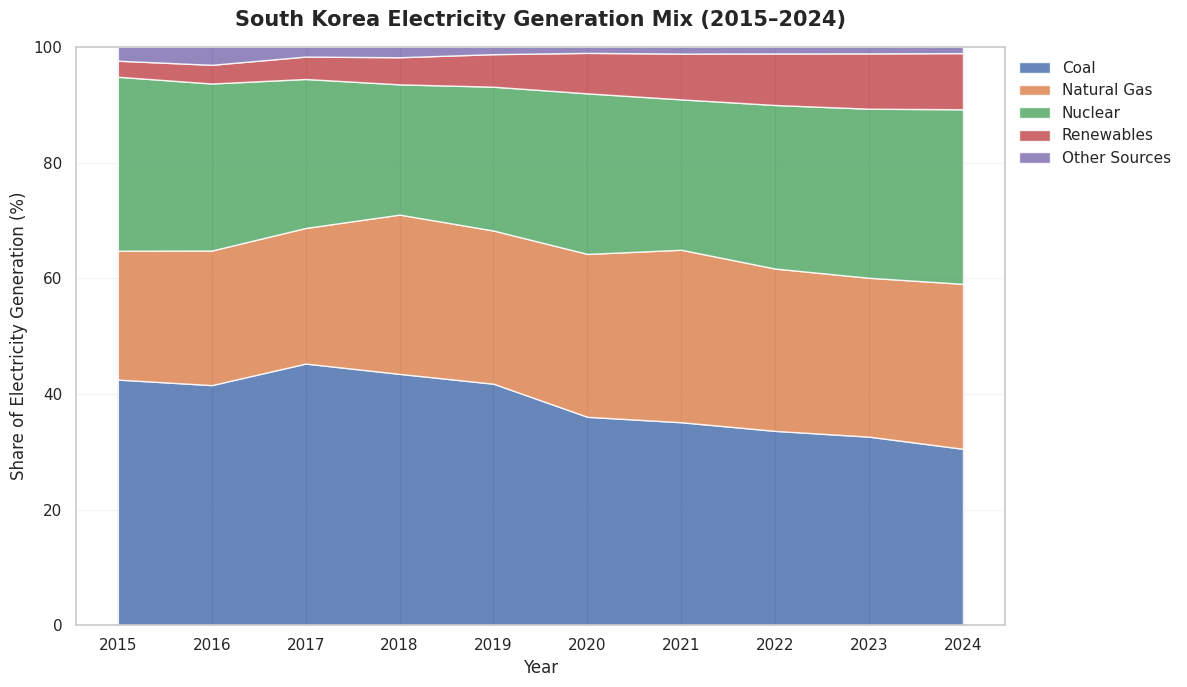

In [68]:


plt.figure(figsize=(12, 7))

plt.stackplot(
    combined_data["date"],
    combined_data["coal_share_pct"],
    combined_data["gas_share_pct"],
    combined_data["nuclear_share_pct"],
    combined_data["renewable_electricity_share_pct"],
    combined_data["other_sources_pct"],
    labels=[
        "Coal",
        "Natural Gas",
        "Nuclear",
        "Renewables",
        "Other Sources"
    ],
    alpha=0.85
)

plt.title(
    "South Korea Electricity Generation Mix (2015–2024)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Share of Electricity Generation (%)", fontsize=12)

plt.xticks(combined_data["date"])
plt.ylim(0, 100)

plt.legend(
    loc="upper left",
    bbox_to_anchor=(1, 1),
    frameon=False
)

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    "Figure_2_Electricity_Generation_Mix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


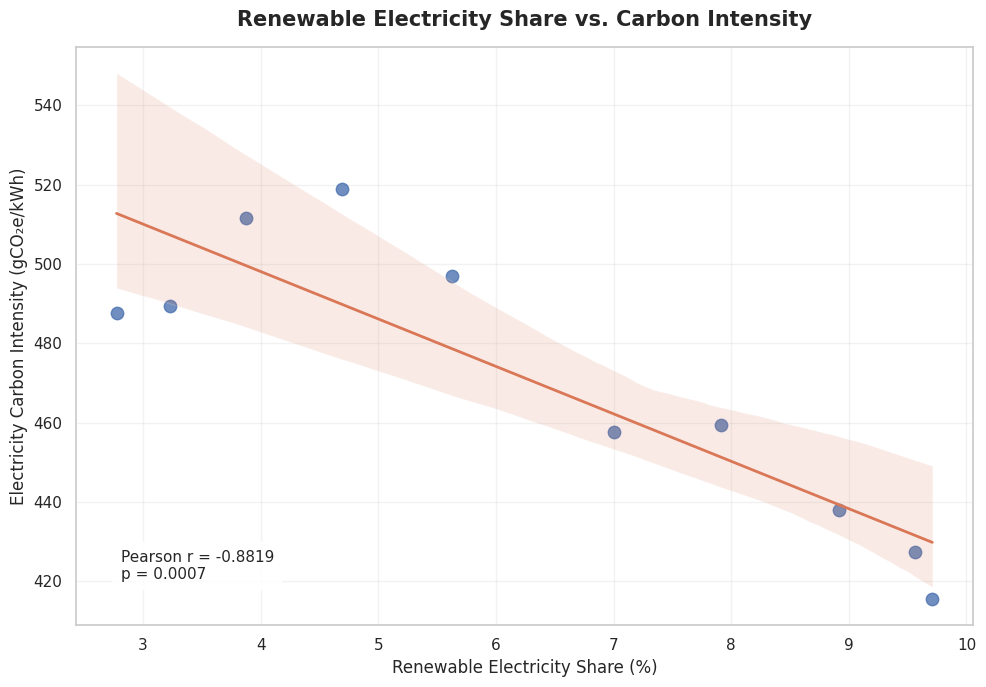

In [69]:



plt.figure(figsize=(10, 7))

sns.regplot(
    data=combined_data,
    x="renewable_electricity_share_pct",
    y="electricity_carbon_intensity_gco2e_kwh",
    scatter_kws={"s": 80, "alpha": 0.8},
    line_kws={"color": "#D97757", "linewidth": 2}
)

plt.title(
    "Renewable Electricity Share vs. Carbon Intensity",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Renewable Electricity Share (%)", fontsize=12)
plt.ylabel("Electricity Carbon Intensity (gCO₂e/kWh)", fontsize=12)

plt.annotate(
    "Pearson r = -0.8819\np = 0.0007",
    xy=(0.05, 0.08),
    xycoords="axes fraction",
    fontsize=11,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9)
)

plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    "Figure_3_Renewables_vs_Carbon_Intensity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


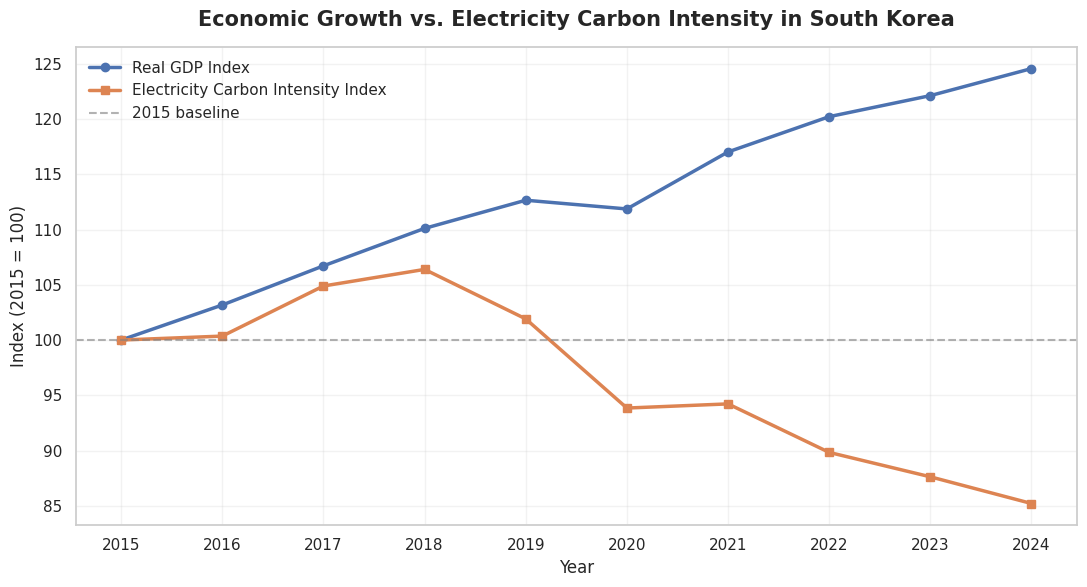

In [70]:

plt.figure(figsize=(11, 6))

plt.plot(
    trend_data["date"],
    trend_data["gdp_index"],
    marker="o",
    linewidth=2.5,
    label="Real GDP Index"
)

plt.plot(
    trend_data["date"],
    trend_data["carbon_index"],
    marker="s",
    linewidth=2.5,
    label="Electricity Carbon Intensity Index"
)

plt.axhline(
    100,
    linestyle="--",
    color="gray",
    alpha=0.6,
    label="2015 baseline"
)

plt.title(
    "Economic Growth vs. Electricity Carbon Intensity in South Korea",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Year", fontsize=12)
plt.ylabel("Index (2015 = 100)", fontsize=12)

plt.xticks(trend_data["date"])
plt.legend(frameon=False)
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    "Figure_4_Economic_Growth_vs_Carbon_Intensity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


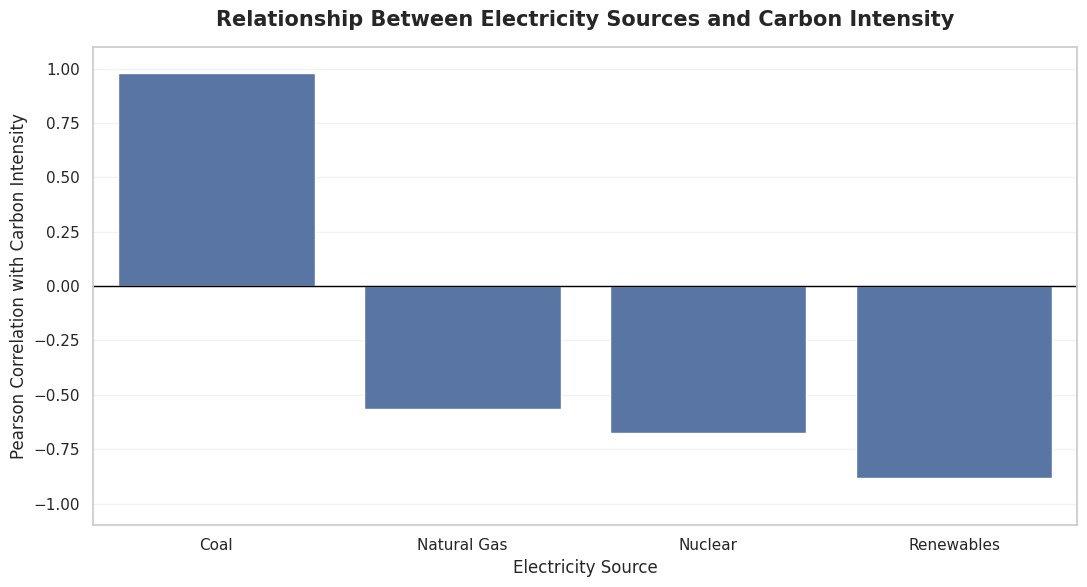

In [71]:

plt.figure(figsize=(11, 6))

sns.barplot(
    data=correlation_results,
    x="Energy Source",
    y="Pearson Correlation"
)

plt.axhline(0, color="black", linewidth=1)

plt.title(
    "Relationship Between Electricity Sources and Carbon Intensity",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Electricity Source", fontsize=12)
plt.ylabel("Pearson Correlation with Carbon Intensity", fontsize=12)

plt.ylim(-1.1, 1.1)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()

plt.savefig(
    "Figure_5_Electricity_Sources_vs_Carbon_Intensity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [72]:

import os

chart_files = [
    "Figure_1_Renewable_Electricity_Adoption.png",
    "Figure_2_Electricity_Generation_Mix.png",
    "Figure_3_Renewables_vs_Carbon_Intensity.png",
    "Figure_4_Economic_Growth_vs_Carbon_Intensity.png",
    "Figure_5_Electricity_Sources_vs_Carbon_Intensity.png"
]

print("RESEARCH VISUALIZATION CHECK")
print("-" * 40)

for file in chart_files:
    if os.path.exists(file):
        print("SAVED:", file)
    else:
        print("MISSING:", file)


RESEARCH VISUALIZATION CHECK
----------------------------------------
SAVED: Figure_1_Renewable_Electricity_Adoption.png
SAVED: Figure_2_Electricity_Generation_Mix.png
SAVED: Figure_3_Renewables_vs_Carbon_Intensity.png
SAVED: Figure_4_Economic_Growth_vs_Carbon_Intensity.png
SAVED: Figure_5_Electricity_Sources_vs_Carbon_Intensity.png


In [73]:

!pip install reportlab

import os
from reportlab.lib.pagesizes import letter
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Image, PageBreak, Table, TableStyle
)
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import inch

print("PDF tools are ready!")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 12.1 MB/s  0:00:00
PDF tools are ready!


In [76]:

import os
from reportlab.lib.pagesizes import letter
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Image, PageBreak, Table, TableStyle, KeepTogether
)
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib import colors
from reportlab.lib.units import inch

figure_files = [
    "Figure_1_Renewable_Electricity_Adoption.png",
    "Figure_2_Electricity_Generation_Mix.png",
    "Figure_3_Renewables_vs_Carbon_Intensity.png",
    "Figure_4_Economic_Growth_vs_Carbon_Intensity.png",
    "Figure_5_Electricity_Sources_vs_Carbon_Intensity.png"
]

missing = [f for f in figure_files if not os.path.exists(f)]

if missing:
    raise FileNotFoundError(f"Missing figure files: {missing}")

# Create PDF
pdf_name = "South_Korea_Renewable_Energy_Research_Report.pdf"

doc = SimpleDocTemplate(
    pdf_name,
    pagesize=letter,
    rightMargin=0.7 * inch,
    leftMargin=0.7 * inch,
    topMargin=0.7 * inch,
    bottomMargin=0.7 * inch
)

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="ReportTitle",
    parent=styles["Title"],
    fontName="Helvetica-Bold",
    fontSize=25,
    leading=31,
    textColor=colors.HexColor("#17365D"),
    alignment=1,
    spaceAfter=18
))

styles.add(ParagraphStyle(
    name="SectionHeading",
    parent=styles["Heading1"],
    fontSize=16,
    leading=20,
    textColor=colors.HexColor("#17365D"),
    spaceBefore=15,
    spaceAfter=8
))

styles.add(ParagraphStyle(
    name="SubHeading",
    parent=styles["Heading2"],
    fontSize=12,
    leading=15,
    textColor=colors.HexColor("#2874A6"),
    spaceBefore=10,
    spaceAfter=5
))

styles.add(ParagraphStyle(
    name="ReportBody",
    parent=styles["BodyText"],
    fontSize=9.5,
    leading=14,
    spaceAfter=8
))

styles.add(ParagraphStyle(
    name="FigureCaption",
    parent=styles["Normal"],
    fontSize=8.5,
    leading=11,
    alignment=1,
    textColor=colors.HexColor("#555555"),
    spaceAfter=12
))

story = []

def heading(text):
    story.append(Paragraph(text, styles["SectionHeading"]))

def subheading(text):
    story.append(Paragraph(text, styles["SubHeading"]))

def paragraph(text):
    story.append(Paragraph(text, styles["ReportBody"]))

def add_figure(filename, caption):
    img = Image(filename)


    max_width = 6.0 * inch
    max_height = 4.0 * inch

    scale = min(
        max_width / img.imageWidth,
        max_height / img.imageHeight
    )

    img.drawWidth = img.imageWidth * scale
    img.drawHeight = img.imageHeight * scale
    img.hAlign = "CENTER"


    story.append(PageBreak())
    story.append(Spacer(1, 8))
    story.append(img)
    story.append(Paragraph(caption, styles["FigureCaption"]))


def add_footer(canvas, document):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.grey)
    canvas.drawString(0.7 * inch, 0.4 * inch,
                      "South Korea Renewable Energy & Economic Analysis")
    canvas.drawRightString(7.8 * inch, 0.4 * inch,
                           f"Page {document.page}")
    canvas.restoreState()


story.append(Spacer(1, 1.25 * inch))
story.append(Paragraph(
    "South Korea Renewable Energy<br/> &amp; Economic Analysis",
    styles["ReportTitle"]
))
story.append(Paragraph(
    "An Analysis of Electricity Generation, Carbon Intensity, "
    "and Economic Growth",
    styles["Heading2"]
))
story.append(Spacer(1, 0.35 * inch))
story.append(Paragraph(
    "<b>Research Period:</b> 2015-2024",
    styles["ReportBody"]
))
story.append(Paragraph(
    "<b>Geographic Focus:</b> South Korea",
    styles["ReportBody"]
))
story.append(Paragraph(
    "<b>Methods:</b> Python, exploratory data analysis, "
    "correlation analysis, and data visualization",
    styles["ReportBody"]
))
story.append(Spacer(1, 1.4 * inch))
story.append(Paragraph(
    "Undergraduate Research Project",
    styles["FigureCaption"]
))
story.append(PageBreak())


heading("Abstract")
paragraph(
    "This study examines the relationship between renewable electricity "
    "adoption, electricity generation composition, carbon intensity, "
    "and economic growth in South Korea from 2015 through 2024. "
    "Publicly available economic and energy datasets were combined and "
    "analyzed using Python, descriptive statistics, correlation analysis, "
    "and visualization."
)
paragraph(
    "Renewable electricity share increased from 2.77% in 2015 to 9.71% "
    "in 2024. Over the same period, coal's share of electricity generation "
    "declined, while natural gas and renewable generation increased. "
    "Renewable electricity share was strongly negatively correlated with "
    "electricity carbon intensity (Pearson r = -0.8819, p = 0.0007). "
    "Real GDP increased by approximately 24.56%, while electricity carbon "
    "intensity declined by approximately 14.79%."
)
paragraph(
    "These findings indicate an association between changes in South "
    "Korea's electricity generation mix and declining electricity carbon "
    "intensity. They do not establish causation."
)

heading("1. Introduction")
paragraph(
    "The transition toward renewable energy presents an important "
    "economic and environmental challenge. Governments must balance "
    "energy security, economic growth, electricity demand, and emissions "
    "reduction while changing their energy systems."
)
paragraph(
    "This project investigates how changes in renewable electricity "
    "adoption in South Korea relate to electricity generation patterns, "
    "electricity carbon intensity, and economic growth."
)
subheading("Research Question")
paragraph(
    "<b>To what extent has renewable energy adoption in South Korea been "
    "associated with changes in electricity generation, carbon intensity, "
    "and economic growth?</b>"
)
subheading("Research Objectives")
paragraph(
    "1. Analyze renewable electricity adoption from 2015 to 2024.<br/>"
    "2. Examine changes in the electricity generation mix.<br/>"
    "3. Investigate the relationship between renewable electricity and "
    "electricity carbon intensity.<br/>"
    "4. Evaluate relationships between economic growth and annual "
    "changes in carbon intensity.<br/>"
    "5. Identify potential economic and environmental implications."
)


heading("2. Data and Methodology")
subheading("Data Sources and Indicators")
paragraph(
    "Economic indicators were obtained from the World Bank's World "
    "Development Indicators: GDP in constant 2015 US dollars "
    "(NY.GDP.MKTP.KD) and annual GDP growth (NY.GDP.MKTP.KD.ZG). "
    "Electricity generation and carbon intensity indicators were obtained "
    "from Our World in Data and its underlying energy data sources."
)
paragraph(
    "The electricity dataset includes renewable electricity share, "
    "electricity carbon intensity in grams of CO2-equivalent per "
    "kilowatt-hour, and generation shares for coal, natural gas, nuclear, "
    "and renewables. A residual category was calculated as other sources."
)
paragraph(
    "The final dataset contains 10 annual observations from 2015 through "
    "2024. Python libraries included Pandas, NumPy, Matplotlib, Seaborn, "
    "SciPy, and Requests."
)
subheading("Analytical Methods")
paragraph(
    "The analysis used descriptive trend analysis, Pearson correlation, "
    "Spearman rank correlation, and a sensitivity analysis excluding "
    "2020 from one GDP-growth comparison. A 5% significance threshold "
    "was used. Correlation measures association rather than causation."
)


heading("3. Results")

subheading("3.1 Renewable Electricity Adoption")
paragraph(
    "Renewable electricity share increased from 2.77% in 2015 to 9.71% "
    "in 2024, an increase of approximately 6.93 percentage points. "
    "Renewables remained a relatively small share of total electricity "
    "generation in 2024, despite substantial growth."
)
add_figure(
    figure_files[0],
    "Figure 1. Renewable electricity adoption in South Korea, 2015-2024."
)

subheading("3.2 Electricity Generation Mix")
paragraph(
    "Between 2015 and 2024, coal declined from 42.48% to 30.51% of "
    "electricity generation. Natural gas increased from 22.28% to 28.52%, "
    "nuclear changed from 30.08% to 30.18%, and renewables increased "
    "from 2.77% to 9.71%. These changes indicate a shifting generation "
    "composition rather than a transition driven by one source alone."
)
add_figure(
    figure_files[1],
    "Figure 2. Electricity generation mix in South Korea, 2015-2024."
)

subheading("3.3 Renewable Electricity and Carbon Intensity")
paragraph(
    "Renewable electricity share had a strong negative association with "
    "electricity carbon intensity. Pearson correlation was -0.8819 "
    "(p = 0.0007), while Spearman correlation was -0.7818 "
    "(p = 0.0075). Years with higher renewable shares tended to have "
    "lower electricity carbon intensity."
)
add_figure(
    figure_files[2],
    "Figure 3. Renewable electricity share versus electricity carbon intensity."
)

subheading("3.4 Economic Growth and Carbon Intensity")
paragraph(
    "From 2015 to 2024, real GDP increased by approximately 24.56%, "
    "while electricity carbon intensity declined by approximately "
    "14.79%. This pattern is consistent with relative decoupling between "
    "economic growth and electricity-sector carbon intensity. It does "
    "not establish economy-wide emissions decoupling."
)
paragraph(
    "Annual GDP growth and annual changes in electricity carbon "
    "intensity had a positive association (Pearson r = 0.7775, "
    "p = 0.0137; Spearman r = 0.7833, p = 0.0125). Years with stronger "
    "GDP growth tended to coincide with less favorable annual changes "
    "in electricity carbon intensity. This short-term relationship does "
    "not contradict the overall 2015-2024 decline."
)
add_figure(
    figure_files[3],
    "Figure 4. Real GDP and electricity carbon intensity indices "
    "(2015 = 100)."
)

subheading("3.5 Electricity Sources and Carbon Intensity")

correlation_table = [
    ["Electricity source", "Pearson r", "p-value"],
    ["Coal", "+0.9781", "<0.0001"],
    ["Natural gas", "-0.5642", "0.0893"],
    ["Nuclear", "-0.6767", "0.0316"],
    ["Renewables", "-0.8819", "0.0007"]
]

table = Table(correlation_table, colWidths=[2.5*inch, 1.5*inch, 1.5*inch])
table.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,0), colors.HexColor("#17365D")),
    ("TEXTCOLOR", (0,0), (-1,0), colors.white),
    ("FONTNAME", (0,0), (-1,0), "Helvetica-Bold"),
    ("GRID", (0,0), (-1,-1), 0.5, colors.lightgrey),
    ("ROWBACKGROUNDS", (0,1), (-1,-1),
     [colors.white, colors.HexColor("#EEF3F8")]),
    ("PADDING", (0,0), (-1,-1), 7),
]))
story.append(table)
story.append(Spacer(1, 10))

paragraph(
    "Coal had a strong positive association with electricity carbon "
    "intensity, while nuclear and renewable electricity had negative "
    "associations. Natural gas also had a negative coefficient, but "
    "its relationship was not statistically significant at the 5% level. "
    "Generation shares are interdependent, so these correlations should "
    "not be interpreted as independent effects."
)
add_figure(
    figure_files[4],
    "Figure 5. Pearson correlations between electricity generation "
    "shares and electricity carbon intensity."
)


heading("4. Discussion")
paragraph(
    "The results show that South Korea's electricity generation mix "
    "changed substantially between 2015 and 2024. Renewable electricity "
    "expanded, coal's generation share declined, and electricity carbon "
    "intensity decreased. The strong negative correlation between "
    "renewable share and carbon intensity is consistent with the "
    "possibility that renewable expansion contributed to a cleaner "
    "electricity mix."
)
paragraph(
    "Economic growth also continued over the study period. Real GDP "
    "increased while electricity carbon intensity declined, suggesting "
    "that economic expansion and improvements in electricity-sector "
    "carbon intensity can occur simultaneously. However, changes in "
    "nuclear generation, fuel efficiency, electricity demand, imports, "
    "and other energy-system factors may also influence these results."
)


heading("5. Limitations")
paragraph(
    "The analysis has several limitations:<br/>"
    "1. The sample contains only 10 annual observations, limiting "
    "statistical power.<br/>"
    "2. Correlations cannot establish causal relationships.<br/>"
    "3. Carbon intensity measures electricity generation, not total "
    "national greenhouse gas emissions.<br/>"
    "4. Generation shares are interdependent because they collectively "
    "represent the electricity mix.<br/>"
    "5. Factors such as electricity demand, fuel prices, policy changes, "
    "and technological developments were not independently controlled.<br/>"
    "6. Secondary datasets may have different measurement methods "
    "or revisions."
)


heading("6. Conclusion")
paragraph(
    "Between 2015 and 2024, South Korea experienced an expansion in "
    "renewable electricity generation alongside a decline in coal's "
    "share of the electricity mix and a reduction in electricity "
    "carbon intensity."
)
paragraph(
    "The analysis identified a strong negative association between "
    "renewable electricity share and electricity carbon intensity. "
    "Real GDP increased while electricity carbon intensity declined "
    "over the same period. Together, these findings suggest that "
    "South Korea's changing electricity generation mix coincided with "
    "improvements in electricity-sector carbon intensity while the "
    "economy continued to grow. Further research is needed to identify "
    "the drivers of these changes."
)

heading("7. Future Research")
paragraph(
    "Future work could compare South Korea with other OECD economies, "
    "examine renewable energy investment and electricity prices, "
    "incorporate electricity demand and policy changes, and use longer "
    "time series and multivariable statistical methods."
)


heading("8. References and Data Documentation")
paragraph(
    "World Bank. World Development Indicators. GDP (constant 2015 US$), "
    "indicator NY.GDP.MKTP.KD; GDP growth (annual %), indicator "
    "NY.GDP.MKTP.KD.ZG."
)
paragraph(
    "Our World in Data. Energy and electricity generation datasets, "
    "including renewable electricity share, electricity generation mix, "
    "and electricity carbon intensity."
)
paragraph(
    "<i>Before public release, add the exact dataset URLs, access dates, "
    "and underlying source documentation from the notebook's data "
    "collection cells.</i>"
)


heading("Project Tools")
paragraph(
    "Python | Pandas | NumPy | Matplotlib | Seaborn | SciPy | "
    "Data Cleaning | Statistical Analysis | Data Visualization"
)

doc.build(
    story,
    onFirstPage=add_footer,
    onLaterPages=add_footer
)

print("SUCCESS: Research report created!")
print("File:", pdf_name)
print("Size:", round(os.path.getsize(pdf_name) / 1024, 1), "KB")

from google.colab import files
files.download(pdf_name)


SUCCESS: Research report created!
File: South_Korea_Renewable_Energy_Research_Report.pdf
Size: 1147.8 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [77]:

from reportlab.lib import colors
from reportlab.lib.pagesizes import letter
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import inch
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image,
    PageBreak, Table, TableStyle, KeepTogether
)
from reportlab.lib.enums import TA_CENTER, TA_LEFT
import os

# --------------------------------------------------
# 1. FILES AND DESIGN
# --------------------------------------------------

pdf_name = "South_Korea_Renewable_Energy_Research_Report.pdf"

figure_files = [
    "Figure_1_Renewable_Electricity_Adoption.png",
    "Figure_2_Electricity_Generation_Mix.png",
    "Figure_3_Renewables_vs_Carbon_Intensity.png",
    "Figure_4_Economic_Growth_vs_Carbon_Intensity.png",
    "Figure_5_Electricity_Sources_vs_Carbon_Intensity.png"
]

missing = [f for f in figure_files if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(f"Missing charts: {missing}")

NAVY = colors.HexColor("#17365D")
BLUE = colors.HexColor("#2874A6")
LIGHT_BLUE = colors.HexColor("#EAF2F8")
DARK = colors.HexColor("#263238")
GREY = colors.HexColor("#64748B")

doc = SimpleDocTemplate(
    pdf_name,
    pagesize=letter,
    rightMargin=0.75 * inch,
    leftMargin=0.75 * inch,
    topMargin=0.72 * inch,
    bottomMargin=0.7 * inch
)

# --------------------------------------------------
# 2. STYLES
# --------------------------------------------------

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="CoverTitle",
    fontName="Helvetica-Bold",
    fontSize=27,
    leading=34,
    alignment=TA_CENTER,
    textColor=NAVY,
    spaceAfter=18
))

styles.add(ParagraphStyle(
    name="CoverSubtitle",
    fontName="Helvetica",
    fontSize=13,
    leading=19,
    alignment=TA_CENTER,
    textColor=GREY,
    spaceAfter=20
))

styles.add(ParagraphStyle(
    name="Section",
    fontName="Helvetica-Bold",
    fontSize=16,
    leading=20,
    textColor=NAVY,
    spaceBefore=12,
    spaceAfter=8,
    keepWithNext=True
))

styles.add(ParagraphStyle(
    name="Subsection",
    fontName="Helvetica-Bold",
    fontSize=11.5,
    leading=15,
    textColor=BLUE,
    spaceBefore=9,
    spaceAfter=5,
    keepWithNext=True
))

styles.add(ParagraphStyle(
    name="BodyCustom",
    fontName="Helvetica",
    fontSize=9.3,
    leading=14,
    textColor=DARK,
    alignment=TA_LEFT,
    spaceAfter=7
))

styles.add(ParagraphStyle(
    name="CaptionCustom",
    fontName="Helvetica-Oblique",
    fontSize=8,
    leading=11,
    alignment=TA_CENTER,
    textColor=GREY,
    spaceBefore=5,
    spaceAfter=10
))

styles.add(ParagraphStyle(
    name="SmallCustom",
    fontName="Helvetica",
    fontSize=8.5,
    leading=12,
    textColor=DARK,
    spaceAfter=5
))

story = []

def H(text):
    story.append(Paragraph(text, styles["Section"]))

def SH(text):
    story.append(Paragraph(text, styles["Subsection"]))

def P(text):
    story.append(Paragraph(text, styles["BodyCustom"]))

def figure(filename, caption):
    img = Image(filename)

    max_width = 6.1 * inch
    max_height = 3.55 * inch

    scale = min(
        max_width / img.imageWidth,
        max_height / img.imageHeight
    )

    img.drawWidth = img.imageWidth * scale
    img.drawHeight = img.imageHeight * scale
    img.hAlign = "CENTER"

    story.append(KeepTogether([
        Spacer(1, 7),
        img,
        Paragraph(caption, styles["CaptionCustom"])
    ]))

# --------------------------------------------------
# 3. TITLE PAGE
# --------------------------------------------------

story.append(Spacer(1, 1.0 * inch))

story.append(Paragraph(
    "SOUTH KOREA<br/>RENEWABLE ENERGY",
    styles["CoverTitle"]
))

story.append(Paragraph(
    "Economic and Environmental Analysis | 2015–2024",
    styles["CoverSubtitle"]
))

accent = Table([[""]], colWidths=[2.0 * inch], rowHeights=[4])
accent.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,-1), BLUE)
]))
story.append(accent)

story.append(Spacer(1, 0.4 * inch))

story.append(Paragraph(
    "An Analysis of Electricity Generation,<br/>"
    "Carbon Intensity, and Economic Growth",
    styles["CoverSubtitle"]
))

story.append(Spacer(1, 0.7 * inch))

cover_info = [
    ["RESEARCH PERIOD", "2015–2024"],
    ["GEOGRAPHIC FOCUS", "South Korea"],
    ["ANALYTICAL APPROACH", "Python and statistical analysis"],
    ["RESEARCH AREA", "Energy and environmental economics"]
]

cover_table = Table(
    cover_info,
    colWidths=[2.0 * inch, 3.5 * inch],
    hAlign="CENTER"
)

cover_table.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (0,-1), LIGHT_BLUE),
    ("TEXTCOLOR", (0,0), (0,-1), NAVY),
    ("FONTNAME", (0,0), (0,-1), "Helvetica-Bold"),
    ("FONTNAME", (1,0), (1,-1), "Helvetica"),
    ("FONTSIZE", (0,0), (-1,-1), 9),
    ("GRID", (0,0), (-1,-1), 0.4, colors.HexColor("#D5DFE8")),
    ("PADDING", (0,0), (-1,-1), 10),
]))

story.append(cover_table)
story.append(Spacer(1, 1.0 * inch))

story.append(Paragraph(
    "Independent Undergraduate Research Project",
    styles["CaptionCustom"]
))

story.append(PageBreak())

# --------------------------------------------------
# 4. ABSTRACT
# --------------------------------------------------

H("Abstract")

P(
    "This study examines the relationship between renewable electricity "
    "adoption, electricity generation composition, carbon intensity, and "
    "economic growth in South Korea from 2015 through 2024. Publicly "
    "available economic and energy datasets were combined and analyzed "
    "using Python, descriptive statistics, correlation analysis, and "
    "data visualization."
)

P(
    "Renewable electricity share increased from 2.77% in 2015 to 9.71% "
    "in 2024. Coal's share of electricity generation declined, while "
    "natural gas and renewable generation increased. Renewable electricity "
    "share was strongly negatively correlated with electricity carbon "
    "intensity (Pearson r = -0.8819, p = 0.0007). Real GDP increased by "
    "approximately 24.56%, while electricity carbon intensity declined "
    "by approximately 14.79%."
)

P(
    "These findings indicate an association between changes in South "
    "Korea's electricity generation mix and declining electricity carbon "
    "intensity. They do not establish causation."
)

# --------------------------------------------------
# 5. INTRODUCTION
# --------------------------------------------------

H("1. Introduction")

P(
    "The transition toward renewable energy presents an important economic "
    "and environmental challenge. Governments must balance energy security, "
    "economic growth, electricity demand, and emissions reduction while "
    "changing their energy systems."
)

P(
    "This project investigates how changes in renewable electricity "
    "adoption in South Korea relate to electricity generation patterns, "
    "electricity carbon intensity, and economic growth."
)

SH("Research Question")

P(
    "<b>To what extent has renewable energy adoption in South Korea been "
    "associated with changes in electricity generation, carbon intensity, "
    "and economic growth?</b>"
)

SH("Research Objectives")

P(
    "1. Analyze renewable electricity adoption from 2015 to 2024.<br/>"
    "2. Examine changes in the electricity generation mix.<br/>"
    "3. Investigate the relationship between renewable electricity and "
    "electricity carbon intensity.<br/>"
    "4. Evaluate relationships between economic growth and annual changes "
    "in carbon intensity.<br/>"
    "5. Identify potential economic and environmental implications."
)

# --------------------------------------------------
# 6. DATA AND METHODOLOGY
# --------------------------------------------------

H("2. Data and Methodology")

SH("Data Sources")

P(
    "Economic indicators were obtained from the World Bank's World "
    "Development Indicators: GDP in constant 2015 US dollars "
    "(NY.GDP.MKTP.KD) and annual GDP growth (NY.GDP.MKTP.KD.ZG). "
    "Electricity generation and carbon intensity indicators were obtained "
    "from Our World in Data and its underlying energy data sources."
)

P(
    "The electricity dataset includes renewable electricity share, "
    "electricity carbon intensity in grams of CO2-equivalent per "
    "kilowatt-hour, and generation shares for coal, natural gas, nuclear, "
    "and renewables. A residual category was calculated as other sources."
)

SH("Analytical Methods")

P(
    "The final dataset contains 10 annual observations from 2015 through "
    "2024. Python libraries included Pandas, NumPy, Matplotlib, Seaborn, "
    "SciPy, and Requests. The analysis used descriptive trend analysis, "
    "Pearson correlation, Spearman rank correlation, and a sensitivity "
    "analysis excluding 2020 from one GDP-growth comparison."
)

P(
    "A 5% significance threshold was used. Correlation coefficients "
    "describe associations and do not establish causal relationships."
)

# --------------------------------------------------
# 7. RESULTS
# --------------------------------------------------

H("3. Results")

SH("3.1 Renewable Electricity Adoption")

P(
    "Renewable electricity share increased from 2.77% in 2015 to 9.71% "
    "in 2024, an increase of approximately 6.93 percentage points. "
    "Renewables remained a relatively small share of total electricity "
    "generation in 2024 despite substantial growth."
)

figure(
    figure_files[0],
    "Figure 1. Renewable electricity adoption in South Korea, 2015–2024."
)

SH("3.2 Electricity Generation Mix")

P(
    "Between 2015 and 2024, coal declined from 42.48% to 30.51% of "
    "electricity generation. Natural gas increased from 22.28% to 28.52%, "
    "nuclear changed from 30.08% to 30.18%, and renewables increased "
    "from 2.77% to 9.71%. These changes indicate a shifting generation "
    "composition rather than a transition driven by one source alone."
)

figure(
    figure_files[1],
    "Figure 2. Electricity generation mix in South Korea, 2015–2024."
)

SH("3.3 Renewable Electricity and Carbon Intensity")

P(
    "Renewable electricity share had a strong negative association with "
    "electricity carbon intensity. Pearson correlation was -0.8819 "
    "(p = 0.0007), while Spearman correlation was -0.7818 (p = 0.0075). "
    "Years with higher renewable shares tended to have lower electricity "
    "carbon intensity."
)

figure(
    figure_files[2],
    "Figure 3. Renewable electricity share versus electricity carbon intensity."
)

SH("3.4 Economic Growth and Carbon Intensity")

P(
    "From 2015 to 2024, real GDP increased by approximately 24.56%, "
    "while electricity carbon intensity declined by approximately 14.79%. "
    "This pattern is consistent with relative decoupling between economic "
    "growth and electricity-sector carbon intensity, not necessarily "
    "economy-wide emissions decoupling."
)

P(
    "Annual GDP growth and annual changes in electricity carbon intensity "
    "had a positive association (Pearson r = 0.7775, p = 0.0137; "
    "Spearman r = 0.7833, p = 0.0125). Years with stronger GDP growth "
    "tended to coincide with less favorable annual changes in electricity "
    "carbon intensity."
)

figure(
    figure_files[3],
    "Figure 4. Real GDP and electricity carbon intensity indices "
    "(2015 = 100)."
)

SH("3.5 Electricity Sources and Carbon Intensity")

P(
    "Coal had a strong positive association with electricity carbon "
    "intensity, while nuclear and renewable electricity had negative "
    "associations. Natural gas also had a negative coefficient, but its "
    "relationship was not statistically significant at the 5% level."
)

correlation_table = [
    ["Electricity source", "Pearson r", "p-value"],
    ["Coal", "+0.9781", "<0.0001"],
    ["Natural gas", "-0.5642", "0.0893"],
    ["Nuclear", "-0.6767", "0.0316"],
    ["Renewables", "-0.8819", "0.0007"]
]

t = Table(
    correlation_table,
    colWidths=[2.6 * inch, 1.5 * inch, 1.5 * inch],
    hAlign="CENTER"
)

t.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,0), NAVY),
    ("TEXTCOLOR", (0,0), (-1,0), colors.white),
    ("FONTNAME", (0,0), (-1,0), "Helvetica-Bold"),
    ("ROWBACKGROUNDS", (0,1), (-1,-1),
     [colors.white, LIGHT_BLUE]),
    ("GRID", (0,0), (-1,-1), 0.4, colors.HexColor("#D5DFE8")),
    ("FONTSIZE", (0,0), (-1,-1), 8.5),
    ("PADDING", (0,0), (-1,-1), 8)
]))

story.append(Spacer(1, 5))
story.append(t)
story.append(Spacer(1, 8))

P(
    "Generation shares are interdependent because they collectively "
    "represent the electricity mix. These correlations should not be "
    "interpreted as independent effects."
)

figure(
    figure_files[4],
    "Figure 5. Pearson correlations between electricity generation "
    "shares and electricity carbon intensity."
)

# --------------------------------------------------
# 8. DISCUSSION AND CONCLUSION
# --------------------------------------------------

H("4. Discussion")

P(
    "South Korea's electricity generation mix changed substantially "
    "between 2015 and 2024. Renewable electricity expanded, coal's "
    "generation share declined, and electricity carbon intensity "
    "decreased. The strong negative correlation between renewable share "
    "and carbon intensity is consistent with the possibility that "
    "renewable expansion contributed to a cleaner electricity mix."
)

P(
    "Economic growth also continued over the study period. Real GDP "
    "increased while electricity carbon intensity declined, suggesting "
    "that economic expansion and improvements in electricity-sector "
    "carbon intensity can occur simultaneously. Other energy-system "
    "factors may also influence these results."
)

H("5. Limitations")

P(
    "The analysis contains only 10 annual observations, limiting "
    "statistical power. Correlations cannot establish causality. The "
    "carbon intensity measure applies to electricity generation rather "
    "than total national emissions. Generation shares are interdependent, "
    "and the analysis does not independently control for electricity "
    "demand, fuel prices, policy changes, or technological developments. "
    "Secondary datasets may also differ in measurement methods or revisions."
)

H("6. Conclusion")

P(
    "Between 2015 and 2024, South Korea experienced an expansion in "
    "renewable electricity generation alongside a decline in coal's share "
    "of the electricity mix and a reduction in electricity carbon intensity."
)

P(
    "The analysis identified a strong negative association between "
    "renewable electricity share and electricity carbon intensity. "
    "Real GDP increased while electricity carbon intensity declined "
    "over the same period. These findings suggest that South Korea's "
    "changing electricity generation mix coincided with improvements "
    "in electricity-sector carbon intensity while the economy continued "
    "to grow. Further research is needed to identify the drivers."
)

H("7. Future Research")

P(
    "Future research could compare South Korea with other OECD economies, "
    "examine renewable energy investment and electricity prices, "
    "incorporate electricity demand and policy changes, and use longer "
    "time series and multivariable statistical methods."
)

H("8. References and Data Documentation")

P(
    "World Bank. World Development Indicators. GDP (constant 2015 US$), "
    "indicator NY.GDP.MKTP.KD; GDP growth (annual %), indicator "
    "NY.GDP.MKTP.KD.ZG."
)

P(
    "Our World in Data. Energy and electricity generation datasets, "
    "including renewable electricity share, electricity generation mix, "
    "and electricity carbon intensity."
)

P(
    "<i>Before public release, add exact dataset URLs, access dates, "
    "and underlying source documentation from the notebook's data "
    "collection cells.</i>"
)

H("Project Tools")

P(
    "Python | Pandas | NumPy | Matplotlib | Seaborn | SciPy | "
    "Data Cleaning | Statistical Analysis | Data Visualization"
)

# --------------------------------------------------
# 9. PAGE FOOTER
# --------------------------------------------------

def footer(canvas, document):
    canvas.saveState()
    width, height = letter

    canvas.setStrokeColor(colors.HexColor("#D5DFE8"))
    canvas.setLineWidth(0.5)
    canvas.line(
        0.75 * inch,
        0.55 * inch,
        width - 0.75 * inch,
        0.55 * inch
    )

    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(GREY)

    canvas.drawString(
        0.75 * inch,
        0.35 * inch,
        "South Korea Renewable Energy & Economic Analysis"
    )

    canvas.drawRightString(
        width - 0.75 * inch,
        0.35 * inch,
        f"{document.page}"
    )

    canvas.restoreState()

# --------------------------------------------------
# 10. BUILD AND DOWNLOAD
# --------------------------------------------------

doc.build(
    story,
    onFirstPage=footer,
    onLaterPages=footer
)

print("SUCCESS: Redesigned research report created.")
print("File:", pdf_name)
print("Size:", round(os.path.getsize(pdf_name) / 1024, 1), "KB")

from google.colab import files
files.download(pdf_name)


SUCCESS: Redesigned research report created.
File: South_Korea_Renewable_Energy_Research_Report.pdf
Size: 1146.9 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [78]:

from google.colab import files

figure_files = [
    "Figure_1_Renewable_Electricity_Adoption.png",
    "Figure_2_Electricity_Generation_Mix.png",
    "Figure_3_Renewables_vs_Carbon_Intensity.png",
    "Figure_4_Economic_Growth_vs_Carbon_Intensity.png",
    "Figure_5_Electricity_Sources_vs_Carbon_Intensity.png"
]

import zipfile

with zipfile.ZipFile("South_Korea_Research_Figures.zip", "w") as zipf:
    for filename in figure_files:
        zipf.write(filename)

files.download("South_Korea_Research_Figures.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>